# 2.04. Байесовские A/B тесты

**План занятия**

1. Частотный и байесовский подходы: философия и практика.
2. Байесовская статистика: приор, правдоподобие, постериор, достоверные интервалы.
3. Байесовский рабочий процесс в PyMC на данных COVID-19.
4. Байесовский A/B-тест на конверсиях и связь с p-value.
5. Подглядывание и ожидаемые потери.
6. A/B-тест на выручке и A/B/C-тест.
7. Сравнение подходов.

### Библиотеки

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import preliz as pz
import pymc as pm
import pymc.math as pmm
import seaborn as sns
from dataclasses import dataclass
from ipywidgets import FloatSlider, IntSlider, interact
from scipy import stats
from scipy.special import betaln

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
sampler_kwargs = {'chains': 4, 'cores': 1, 'tune': 1000, 'draws': 1000, 'random_seed': RANDOM_SEED, 'progressbar': False}

## Байесовский и частотный подходы

**Исторический контекст и философские различия: Частотный и байесовский подходы в статистике**

Возникновение современных статистических парадигм уходит корнями в фундаментальный вопрос эпистемологии: **какова природа вероятности?** Два принципиально разных ответа на этот вопрос сформировали дихотомию, определяющую развитие статистической науки на протяжении трех столетий. **Частотный (Classical/Frequentist)** подход, ассоциируемый с именами Рональда Фишера, Ежи Неймана и Карла Пирсона, и **байесовский (Bayesian)** подход, восходящий к работам Томаса Байеса и Пьера-Симона Лапласа, представляют не просто альтернативные методы расчета, но принципиально различные философские системы интерпретации неопределенности.

**Гносеологические истоки: две концепции вероятности**

В основе расхождения лежит противоположное понимание самой категории вероятности.

* **Частотный подход**

Частотный подход, достигший расцвета в первой половине XX века, трактует вероятность как **объективную меру долгосрочной частоты события**. Эта концепция предполагает мысленный эксперимент с бесконечным числом идентичных повторений: вероятность события $P(A)$ есть предел его относительной частоты при неограниченном росте испытаний. Например, вероятность выпадения орла у "честной" монеты строго равна 0.5, поскольку лишь это значение обеспечивает сходимость относительной частоты к константе при бесконечных подбрасываниях. Такой взгляд естественным образом порождает ключевые принципы частотной статистики: параметры модели (скажем, истинная конверсия $p$) считаются фиксированными, хотя и неизвестными константами, лишенными вероятностных распределений, тогда как данные интерпретируются как случайные реализации, порожденные этими параметрами. Центральным становится понятие повторяемости эксперимента — валидность статистических выводов (оценок, p-value, доверительных интервалов) проверяется через их поведение в гипотетической бесконечной серии идентичных исследований. Хотя декларируемая объективность частично нивелируется субъективностью выбора модели и уровня значимости, частотная парадигма стремится минимизировать влияние исследователя на результат.

* **Байесовский подход**

Байесовский подход, получивший формальное основание в работе Байеса (1763) и развитый Лапласом, предлагает радикально иную эпистемологическую позицию. Здесь вероятность есть **субъективная мера степени уверенности в истинности утверждения**, основанная на доступной информации. Такой взгляд не требует мысленных повторений эксперимента — вероятность становится инструментом рационального мышления в условиях неполного знания. Например, утверждение "вероятность дождя завтра равна 70%" отражает не частоту метеорологических событий, а степень обоснованной убежденности говорящего с учетом данных метеоррадаров, синоптических карт и прошлого опыта. Это влечет кардинальное отличие в аксиоматике: параметры модели (такие как конверсия $p$) суть случайные величины, наделенные распределениями вероятностей, количественно выражающими нашу неопределенность относительно их значений. Наблюдаемые данные при этом фиксированы — они не "генерируются", а являются данностью. Статистический вывод превращается в последовательное обновление убеждений: априорное распределение (prior), кодирующее знания до эксперимента, преобразуется в апостериорное распределение (posterior) через механизм условной вероятности при поступлении новых данных. Явное включение предварительных знаний делает байесовский подход неизбежно субъективным, но одновременно предоставляет мощный аппарат для инкорпорирования экспертной информации и результатов предыдущих исследований.

**Философское противостояние и методологические следствия**

Философские основания подходов порождают контрастные принципы принятия решений. Частотная парадигма, укорененная в позитивизме, рассматривает мир как объективную реальность с фиксированными параметрами. Её методология нацелена на создание процедур с гарантированными долгосрочными свойствами: 95% доверительный интервал должен покрывать истинный параметр ровно в 95% гипотетических повторений, а критерий значимости — контролировать частоту ложных срабатываний. Ключевой инструмент — **p-value** — интерпретируется как вероятность наблюдать данные столь же или более экстремальные, чем полученные, при условии истинности нулевой гипотезы. Важно подчеркнуть: это не вероятность того, что гипотеза верна или неверна, а мера согласия данных с моделью в рамках частотной метафоры повторяемости.

Байесовская методология, близкая к философскому прагматизму и субъективному байесианству де Финетти, переносит фокус на обновление знаний. Апостериорное распределение даёт прямые вероятностные утверждения: "вероятность того, что вариант A превосходит B, составляет 92%" или "с вероятностью 90% прирост конверсии лежит в интервале [0.3%, 2.7%]". Такие формулировки естественным образом соответствуют интуитивному запросу лиц, принимающих решения. Более того, байесовский вывод когерентен в техническом смысле — соблюдение аксиом вероятности гарантирует непротиворечивость выводов, чего нельзя строго утверждать о частотных методах.

Парадокс Линдли (1957) ярко демонстрирует методологический разрыв. Рассмотрим ситуацию: при большом объёме данных частотный критерий даёт маленькое p-value (<0.01), формально требуя отвергнуть точечную H0. Однако байесовский анализ с положительной априорной вероятностью точечной H0 и широким приором на альтернативе может дать высокую апостериорную вероятность H0. Причина в том, что широкий приор размазывает альтернативу по большим эффектам, а наблюдаемый маленький эффект плохо с ними согласуется. Парадокс показывает, что ответ зависит от постановки: оценка эффекта и сравнение точечной H0 с альтернативой — разные задачи.

**Практическая конвергенция и области применения**

Несмотря на философские расхождения, при определённых условиях методы демонстрируют конвергенцию. Теорема Бернштейна — фон Мизеса устанавливает, что при увеличении объёма данных апостериорное распределение сходится к нормальному с центром в частотной оценке и дисперсией, обратной информации Фишера.

$$
|| P(θ|x_1, \cdots x_n) - N(\hat{\theta}_n, n^{-1}\mathcal{I}(\theta_0)^{-1})||_{TV} \rightarrow 0
$$

Более того, многие частотные процедуры допускают байесовскую интерпретацию: например, МНК-оценка совпадает с апостериорным средним при гауссовских ошибках и равномерном априорном распределении. Однако на малых выборках или при наличии содержательных априорных знаний различия становятся критически важными.

Исторически частотные методы доминировали в прикладных науках XX века благодаря развитой теории проверки гипотез и доступности таблиц распределений. Ситуация начала меняться с компьютерной революцией: методы Монте-Карло для байесовских вычислений (Metropolis-Hastings, Gibbs sampling) преодолели аналитические ограничения, а рост мощности процессоров сделал их доступными. Сегодня выбор парадигмы определяется конкретной задачей. Частотный подход сохраняет преимущества в задачах, требующих стандартизированных протоколов: клинические испытания (регулируемые ICH E9), индустриальный контроль качества (карты Шухарта), ситуации с жёсткими требованиями к контролю ошибок I/II рода. Его сила — в воспроизводимости процедур и независимости от субъективных предпосылок, что критично в регулируемых отраслях.

Байесовский подход демонстрирует превосходство в динамичных средах, где решения принимаются последовательно. В онлайн-экспериментах его часто ценят за прямую формулировку результата и учёт денег в решении. Но важно: байесовский вывод сам по себе **не решает проблему подглядывания** с точки зрения ошибки первого рода, это мы проверим на симуляции. При ограниченных данных (пилотные исследования, редкие события) включение априорной информации через соответствующие распределения (Beta для пропорций, Gamma для частот) может повысить эффективность, если априорная информация верна. Интерпретируемость вывода («вероятность улучшения 95%») ускоряет коммуникацию с бизнес-аудиторией.

**Эволюционный синтез и современные тенденции**

Историческое противостояние постепенно сменяется методологическим синтезом. С одной стороны, частотные заимствуют байесовские идеи: байесовские p-value, эмпирические байесовские методы (James-Stein оценка), false discovery rate (FDR) контролируют ожидаемую долю ошибок, что ближе к байесовскому духу. С другой — байесовцы разрабатывают "объективные" априорные распределения, минимизирующие влияние исследователя. Возникающие гибридные методы (frequentist-Bayes) используют байесовские модели для генерации гипотез и частотные методы для их валидации.

В контексте A/B тестирования этот синтез проявляется в разработке адаптивных дизайнов, где байесовские методы применяются для промежуточных решений (остановка/продолжение набора), а финальный вывод верифицируется частотными критериями. Подобная конвергенция отражает общую тенденцию: современная прикладная статистика всё реже выступает как "чистая" парадигма, а скорее как инструментарий, где выбор метода определяется не доктриной, а природой данных, объёмом выборки, наличием априорной информации и требуемой формой ответа. Понимание же исторических корней и философских оснований остаётся необходимым условием для осознанного выбора в этом расширяющемся методологическом пространстве.

## Байесовская статистика

### Теоретическая справка

В основе всей байесовской статистики лежит формула, выведенная Томасом Байесом в XVIII веке. Пусть $A$ и $B$ — два события в вероятностном пространстве, причём $P(B)>0$. Теорема Байеса утверждает, что условная вероятность события $A$, при условии что произошло $B$, выражается через  
$$
P(A\mid B) = \frac{P(B\mid A)\,P(A)}{P(B)} = \frac{P(B\mid A)\,P(A)}{\displaystyle \sum_{A'}P(B\mid A')\,P(A')}
$$

* $P(A)$ называется априорной вероятностью
* $P(B\mid A)$ — условной вероятностью наблюдения $B$ при гипотезе $A$.
* $P(B)= \displaystyle\sum_{A'}P(B\mid A')\,P(A')$ — нормировка, здесь сумма идёт по всем взаимоисключающим гипотезам.


В большинстве статистических задач объектом интереса является не дискретный «список гипотез», а непрерывный вектор параметров $\theta \in \Theta$ и наблюдения (данные) $D$. В этом случае мы оперируем плотностями $p(\theta)$ и $p(D\mid\theta)$, а теорема Байеса переписывается в виде

$$
p(\theta\mid D) = \frac{p(D\mid \theta)\,p(\theta)}{p(D)} = \frac{p(D\mid \theta)\,p(\theta)}{\displaystyle\int_{\Theta}p(D\mid \theta)\,p(\theta)\,d\theta}
$$


В этой формуле
* $p(\theta)$ есть априорная плотность - отражает наше начальное представление о параметре до получения данных;  
* $p(D\mid\theta)$ есть likelihood, «правдоподобие» данных - показывает, с какой «силой» каждая гипотеза $\theta$ объясняет наблюдения;  
* $p(D)=\int_{\Theta}p(D\mid \theta)\,p(\theta)\,d\theta$ - маргинальное правдоподобие (evidence) и играет роль нормировочной константы, гарантируя, что $p(\theta\mid D)$ интегрируется в единицу.

* $p(\theta\mid D)$ — апостериорная плотность, обновлённое распределение параметра после учёта данных.


Таким образом, базовый путь байесовского вывода состоит из следующих шагов:

1. **Выбор приора**

  Приор формализует знания о параметрах до наблюдения данных. Выбор приора — ключевой аспект байесовского моделирования, т.к. неправильный его выбор может напрямую изменить результат, посчитанный по формуле Байеса. Приоры бывают 2 видов:

  * **Неинформативные** -  Минимизируют влияние на постериорное распределение. Например, $\text{Beta}(1, 1)$ равномерно на $[0, 1]$, а $\text{Beta}(0.5, 0.5)$ — приор Джеффриса.

  * **Информативные** - Кодируют экспертные знания о распределении параметра. ($\text{Beta}(50, 50)$ для 50% конверсии или $\text{Gamma}$ с формой 16 и масштабом 125 для ARPU со средним значением в 2000)

  Выбор приора — это баланс между точностью описания знаний и **сопряжённостью**, которая упрощает расчёт.

2. **Построение правдоподобия**

  На этом этапе задаётся вероятностная модель данных при данном гипотетическом значении параметра $\theta$. То есть, определяется, как данные генерируются в теории, если известно значение $\theta$. Обычно это выглядит как функция вероятности (или плотности) данных $p(D\,|\,\theta)$.

Например, для бинарных исходов это биномиальное правдоподобие (константа $\binom{n}{x}$ от $\theta$ не зависит и на постериор не влияет):
$$
p(D\mid \theta) \propto \theta^{x} (1 - \theta)^{n - x}
$$

где $x$ — количество успехов, $n$ — общее число испытаний.

3. **Обновление постериорных знаний**

  Этот шаг — основной в байесовском выводе, он позволяет объединить наши начальные предположения и новые данные, чтобы получить полное обновлённое понимание вероятностей параметров. Используя формулу Байеса, мы вычисляем апостериорное распределение — обновлённую вероятность гипотезы $\theta$ после получения данных.  

  Этот момент самый тяжёлый: маргинальное правдоподобие обычно нельзя посчитать аналитически. Есть две развилки:

  * Удобный выбор приора: если мы выбираем приор таким образом, чтобы он был **[сопряжён](https://ru.wikipedia.org/wiki/Сопряжённое_априорное_распределение)** с правдоподобием, то мы можем аналитически подсчитать сразу апостериорное распределение, минуя подсчёты маргинального правдоподобия. Например, для конверсий (бернуллиевской величины) часто приором берут $\text{Beta}(\alpha, \beta)$, что гарантирует, что постериор будет тогда распределён как $\text{Beta}(\alpha + x, \beta + n - x)$.

  * Численные методы: если не получается выбрать сопряжённый приор, то остаётся только применять численные методы для подсчёта маргинального правдоподобия:
    * [MCMC (Monte-Carlo Markov Chain)](https://ru.wikipedia.org/wiki/Марковская_цепь_Монте-Карло) - строит цепи Маркова, у которых стационарное распределение — искомый апостериор. Это обеспечивает возможность генерировать выборки из апостериорного распределения, по которым далее можно делать оценки всей выборки. Основными [алгоритмами](https://m-clark.github.io/docs/ld_mcmc/) являются алгоритм Гиббса, Метрополиса–Гастингса. алгоритм Ланжевена, а в PyMC по умолчанию используется NUTS.
    * [Вариационный вывод (Variational Inference)](https://ermongroup.github.io/cs228-notes/inference/variational/) - аппроксимирует апостериорное распределением из параметрического семейства $q_\phi(\theta)$, минимизируя расстояние Кульбака-Лейблера (KL-дивергенцию).

    * [Метод Лапласа](https://en.wikipedia.org/wiki/Laplace%27s_method) - аппроксимирует лог-апостериор квадратичной функцией около его моды, что позволяет получить приближенную нормальную аппроксимацию.

4. **Интерпретация постериорных значений**

  Как только мы обновили приорные знания с помощью правдободобия и данных, мы получаем апостериорное распределения параметра $\theta$. В байесовской парадигме неопределённость о параметре описывается целым распределением. Это, в свою очередь, имеет очень приятное последствие - более простая интерпретация. Аналогом **доверительных интервалов (confidence intervals)** в частотном подходе здесь будут **достоверные интервалы (credible intervals)**. Давайте сравним их интерпретацию:

  * **95% Доверительный интервал** - при многократном сэмплировании 95% доверительных интервалов будут покрывать действительное значение параметра $\theta$;
  * **95% Достоверный интервал** - 95% вероятность, что $\theta$ лежит в данном интервале;

  Достоверный интервал отвечает на вопрос, который мы обычно хотим задать. Но это утверждение верно при условии приора и модели, а с широким приором и большой выборкой численно интервал совпадает с доверительным.

#### Кейс для понимания

Посчитаем постериор с сопряжённым приором на кейсе.

Компания MM Manufacturing славится производством высокоточных весов. Их система первоклассная, обеспечивающая практически идеальную калибровку большинства изделий. Однако в последнее время возникла необычная проблема – всплеск жалоб клиентов на неидеальные веса. В ответ на это MM Manufacturing ввела дополнительный уровень человеческой проверки, чтобы гарантировать безупречность всех отправляемых клиентам весов.

Чтобы проанализировать динамику фактических производственных весов, они поручили своей команде Data Science проанализировать вероятность появления таких нестандартных весов и, что ещё важнее, отслеживать распределение таких случаев, чтобы понять, как повысить производительность. К счастью, вся продукция досконально документируется сходя с конвейера.

Подход команды основан на байесовской калибровке. Каждый месяц они обновляют функцию плотности вероятности бета-распределения, чтобы оценить аномалию в весах и её динамику с течением времени. Для этого они используют данные с конвейера, которые служат наблюдениями для окончательного определения апостериорной вероятности. Им также необходимо установить приорное распределение, которое может основываться на исторических данных, знаниях предметной области или неспецифическом, неинформативном распределении.

Если априор равен $\text{Beta}(\alpha_0, \beta_0)$, а среди $n$ весов $x$ откалиброваны правильно, то постериор равен:

$$
\text{Beta}(\alpha_0 + x,\ \beta_0 + n - x)
$$

Правдоподобие как функция $\theta$ имеет форму $\text{Beta}(x + 1, n - x + 1)$, поэтому на графике его удобно показывать бета-плотностью.


Что касается выбора априорной вероятности, они изначально выбирают неинформативную, представленную $\text{Beta}(1, 1)$ (равномерное распределение, как показано ниже), что минимизирует влияние априорной вероятности на апостериорную и делает основную ставку на данные наблюдений.

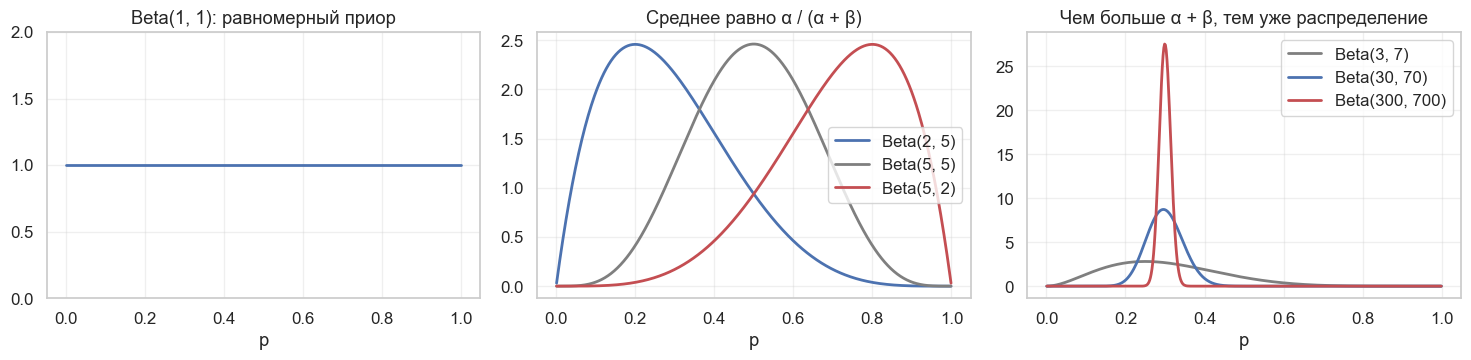

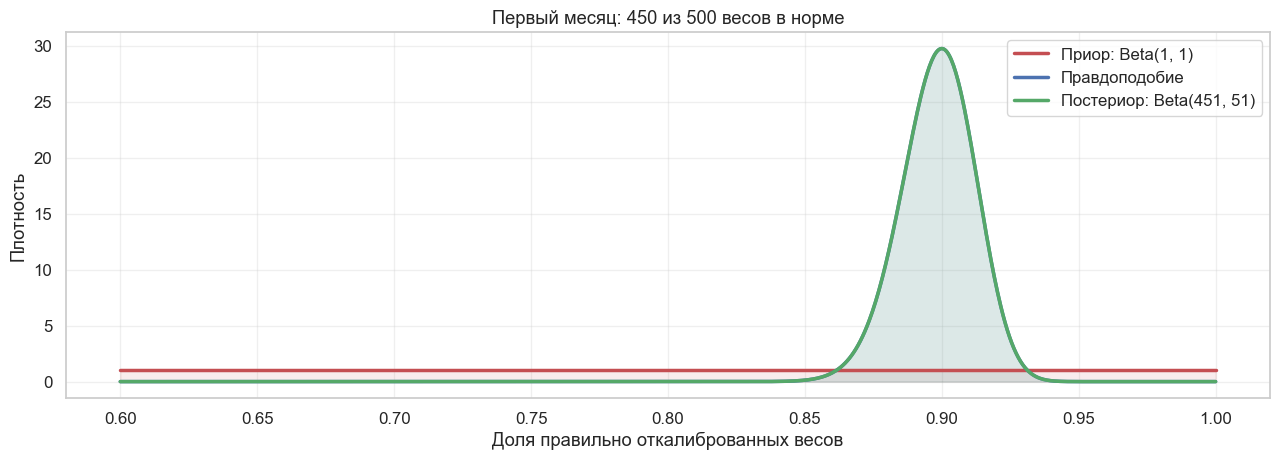

In [2]:
x = np.linspace(0.001, 0.999, 500)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
axes[0].plot(x, stats.beta.pdf(x, 1, 1), color=BLUE, linewidth=2)
axes[0].set(title='Beta(1, 1): равномерный приор', ylim=(0, 2), xlabel='p')
for (a, b), color in zip([(2, 5), (5, 5), (5, 2)], [BLUE, GRAY, RED]):
    axes[1].plot(x, stats.beta.pdf(x, a, b), color=color, linewidth=2, label=f'Beta({a}, {b})')
axes[1].set(title='Среднее равно α / (α + β)', xlabel='p')
axes[1].legend()
for scale, color in zip([1, 10, 100], [GRAY, BLUE, RED]):
    axes[2].plot(x, stats.beta.pdf(x, 3 * scale, 7 * scale), color=color, linewidth=2, label=f'Beta({3 * scale}, {7 * scale})')
axes[2].set(title='Чем больше α + β, тем уже распределение', xlabel='p')
axes[2].legend()
plt.tight_layout()
plt.show()


def beta_update(prior_alpha: float, prior_beta: float, successes: int, total: int) -> tuple:
    """Возвращает параметры постериора для бета-приора и биномиальных данных."""
    return prior_alpha + successes, prior_beta + total - successes


def plot_beta_update(prior: tuple, successes: int, total: int, title: str, xlim: tuple = (0.6, 1.0), ax=None) -> tuple:
    """Показывает приор, правдоподобие и постериор."""
    ax = ax or plt.subplots(figsize=(13, 4.8))[1]
    posterior = beta_update(*prior, successes, total)
    x = np.linspace(*xlim, 1000)
    curves = [(prior, RED, f'Приор: Beta({prior[0]:g}, {prior[1]:g})'), ((successes + 1, total - successes + 1), BLUE, 'Правдоподобие'),
              (posterior, GREEN, f'Постериор: Beta({posterior[0]:g}, {posterior[1]:g})')]
    for parameters, color, label in curves:
        density = stats.beta.pdf(x, *parameters)
        ax.plot(x, density, color=color, linewidth=2.5, label=label)
        ax.fill_between(x, density, color=color, alpha=0.1)
    ax.set(title=title, xlabel='Доля правильно откалиброванных весов', ylabel='Плотность')
    ax.legend()
    return posterior


month1 = plot_beta_update((1, 1), 450, 500, 'Первый месяц: 450 из 500 весов в норме')
plt.tight_layout()
plt.show()

Постериор практически совпадает с правдоподобием: при равномерном приоре так и должно быть.

В следующем месяце у нас новые данные, и приором становится постериор предыдущего месяца.

Предположим, что MM Manufacturing внесла изменения в систему, и теперь аномальны только 6% весов.

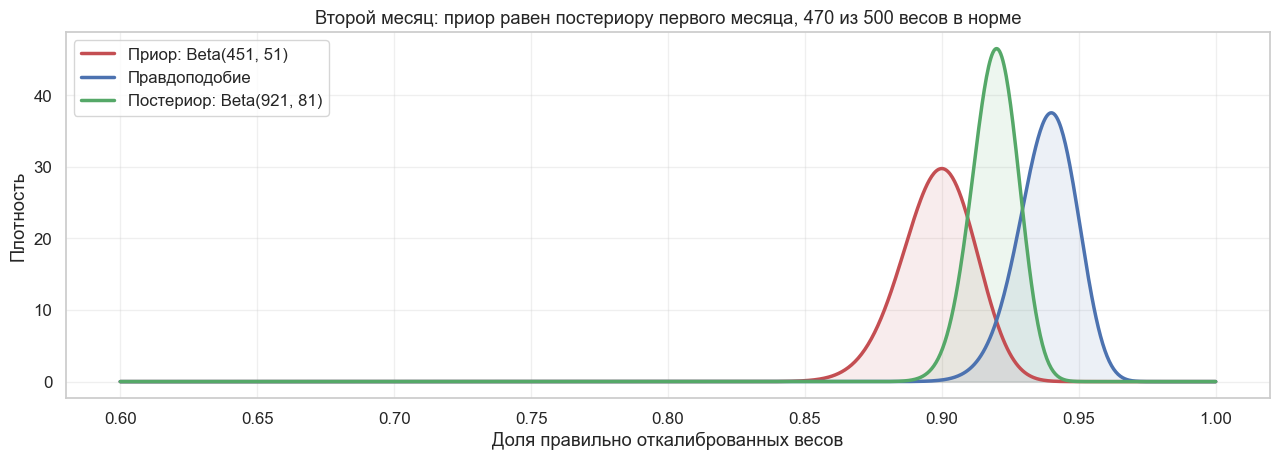

In [3]:
plot_beta_update(month1, 470, 500, 'Второй месяц: приор равен постериору первого месяца, 470 из 500 весов в норме')
plt.tight_layout()
plt.show()

Теперь приор информативен, и постериор лежит между старым значением и новыми данными: он стал уже, но всё ещё отстаёт от текущей доли брака. Это важное предупреждение: если система изменилась, накопленный приор тянет оценку к старому значению.

**Попробуйте сами.** Эта ячейка интерактивная: меняйте силу приора и объём данных. Статичные версии показаны выше.

In [4]:
def beta_demo(prior_mean: float = 0.7, prior_strength: int = 50, share: float = 0.9, n: int = 100) -> None:
    """Показывает, как постериор зависит от силы приора и объёма данных."""
    prior = (prior_mean * prior_strength, (1 - prior_mean) * prior_strength)
    posterior = plot_beta_update(prior, int(share * n), n, f'Среднее постериора: {posterior_mean(*prior, int(share * n), n):.3f}', xlim=(0, 1))
    plt.tight_layout()
    plt.show()


def posterior_mean(alpha: float, beta: float, successes: int, total: int) -> float:
    """Считает среднее постериора."""
    return (alpha + successes) / (alpha + beta + total)


interact(beta_demo,
         prior_mean=FloatSlider(value=0.7, min=0.05, max=0.95, step=0.05, description='Среднее приора'),
         prior_strength=IntSlider(value=50, min=2, max=2000, step=2, description='α + β'),
         share=FloatSlider(value=0.9, min=0.05, max=0.95, step=0.05, description='Доля в данных'),
         n=IntSlider(value=100, min=10, max=2000, step=10, description='n'));

### Байесовская статистика в PyMC

PyMC — это библиотека вероятностного программирования для Python, которая позволяет создавать байесовские модели и обучать их методами Монте-Карло с цепями Маркова (MCMC). Вместе с ней устанавливается ArviZ, с помощью которой удобно визуализировать оценки и распределения.

Ниже мы демонстрируем байесовский рабочий процесс на основе данных о случаях COVID-19, показывая, как перейти от самых простых, нереалистичных моделей к более сложным формулировкам, подчёркивая критическую роль проверки и валидации модели на каждом этапе. Здесь мы не стремимся разработать современную эпидемиологическую модель, а скорее демонстрируем, как перейти от простой модели к более сложной.

Работа в байесовской парадигме — итеративный процесс постепенного улучшения модели.

Базовый [Workflow](https://sites.stat.columbia.edu/gelman/research/unpublished/Bayesian_Workflow_article.pdf) состоит из следующих шагов:

* **Conceptual model building:** перевести знания о предметной области в статистические предположения;
* **Prior predictive simulation:** проверить, что приоры порождают разумные данные;
* **Computational implementation:** написать модель и убедиться, что она запускается;
* **Fitting and diagnostics:** оценить параметры и проверить сходимость;
* **Model evaluation:** оценить соответствие модели данным через апостериорную предиктивную проверку;
* **Model comparison:** систематически сравнить альтернативные модели;
* **Model expansion or simplification:** усложнить или упростить модель по итогам;
* **Decision analysis:** использовать модель для прогнозов и решений.

In [5]:
JHU_URL = ('https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/'
           'csse_covid_19_time_series/time_series_covid19_confirmed_global.csv')


def load_country(country: str, last_date: str) -> pd.DataFrame:
    """Загружает накопленные случаи страны начиная с дня, когда их стало не меньше 100."""
    raw = pd.read_csv(JHU_URL)
    series = raw[raw['Country/Region'] == country].drop(columns=['Province/State', 'Country/Region', 'Lat', 'Long']).sum()
    frame = pd.DataFrame({'date': pd.to_datetime(series.index, format='%m/%d/%y'), 'confirmed': series.values.astype(int)})
    frame = frame[(frame['confirmed'] >= 100) & (frame['date'] <= pd.Timestamp(last_date))].reset_index(drop=True)
    frame['days_since_100'] = np.arange(len(frame))
    return frame


df_full = load_country('Germany', '2020-07-31')
df_country = df_full.head(30)
t = df_country['days_since_100'].to_numpy()
confirmed = df_country['confirmed'].to_numpy()
df_country.head()

,date,confirmed,days_since_100
0,2020-03-01,117,0
1,2020-03-02,150,1
2,2020-03-03,188,2
3,2020-03-04,262,3
4,2020-03-05,400,4


Далее мы приступим к разработке модели распространения. Эти модели изначально будут простыми (и некачественными), но мы будем их итеративно улучшать. Рекомендуемый рабочий процесс при разработке собственных моделей:

1. Построить график данных — понять закономерности и особенности

2. Построить модель — начать с простого, постепенно усложняя

3. Проверить априорные прогнозы — убедиться, что приоры порождают осмысленные данные

4. Адаптация модели — оценить параметры на основе данных

5. Оценить сходимость — проверить вычислительную надежность

6. Проверить соответствие модели — сравнить прогнозы с наблюдениями

7. Улучшить модель — устранить выявленные недостатки

#### Шаг 1. Визуализация данных

Мы рассмотрим случаи COVID-19 в Германии. Сначала мы рассмотрим только первые 30 дней после того, как число случаев превысило 100, а затем рассмотрим все данные.

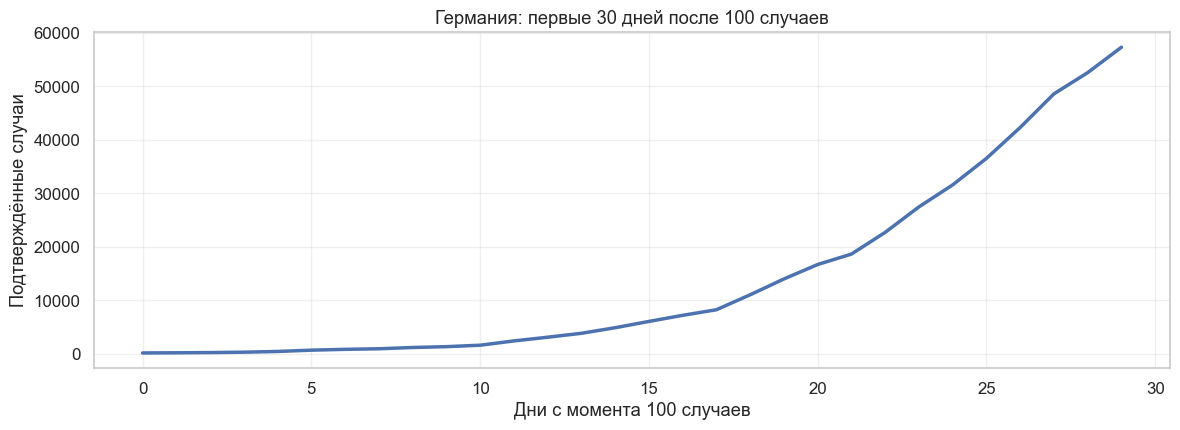

In [6]:
def exponential_growth(a, b, t):
    """Считает a * (1 + b) ** t через логарифм: при широких приорах сэмплер пробует очень большие b."""
    return a * pm.math.exp(pm.math.clip(t * pm.math.log(pm.math.maximum(1 + b, 1e-6)), -300, 300))


def plot_paths(samples: np.ndarray, title: str, ylim: tuple = None, xlim: tuple = None, observed: np.ndarray = None, log: bool = False, ax=None) -> None:
    """Рисует траектории из предиктивного распределения и наблюдаемые данные."""
    ax = ax or plt.subplots(figsize=(12, 4.8))[1]
    ax.plot(samples[:, :100], color=BLUE, linewidth=0.5, alpha=0.3)
    if observed is not None:
        ax.plot(observed, color=RED, marker='o', markersize=4, linewidth=1.5, label='Данные')
        ax.legend()
    ax.set(title=title, xlabel='Дни с момента 100 случаев', ylabel='Число случаев', ylim=ylim, xlim=xlim)
    if log:
        ax.set_yscale('log')


fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(t, confirmed, color=BLUE, linewidth=2.5)
ax.set(title='Германия: первые 30 дней после 100 случаев', xlabel='Дни с момента 100 случаев', ylabel='Подтверждённые случаи')
plt.tight_layout()
plt.show()

Посмотрите на график выше и подумайте, какую модель вы бы построили, чтобы отразить эту закономерность. Какая математическая функция могла бы описать этот рост?

#### Шаг 2. Построение модели-бейзлайна

Траектория кумулятивного числа случаев выглядит экспоненциальной. Это соответствует данным эпидемиологии, поскольку на ранних стадиях эпидемии оно растёт экспоненциально.

In [7]:
with pm.Model() as model_exp1:
    a = pm.Normal('a', mu=0, sigma=100)            # свободный член
    b = pm.Normal('b', mu=0.3, sigma=0.3)          # темп роста
    growth = exponential_growth(a, b, t)
    eps = pm.HalfNormal('eps', 100)                # шум
    pm.Normal('obs', mu=growth, sigma=eps, observed=confirmed)

Перед подгонкой подумайте: какие предположения делает эта модель? Есть ли какие-либо проблемы, которые вы можете определить, исходя только из спецификации модели? Что бы вы сделали иначе?

#### Шаг 3. Проверка приоров

Даже не обучая модель на наших данных, мы можем сгенерировать потенциальные данные из приоров. Обычно у нас меньше интуиции о пространстве параметров, где заданы приоры, и больше — о том, какие данные мы ожидаем увидеть. Таким образом, априорная предиктивная проверка позволяет нам убедиться, что модель может генерировать те типы данных, которые мы ожидаем увидеть.

Процесс работает следующим образом:

* Выбрать значение из приора $\theta_i$
* Сгенерировать набор данных $x_i \sim f(\theta_i)$
где $f$ — наша функция правдоподобия
* Повторить $n$ раз

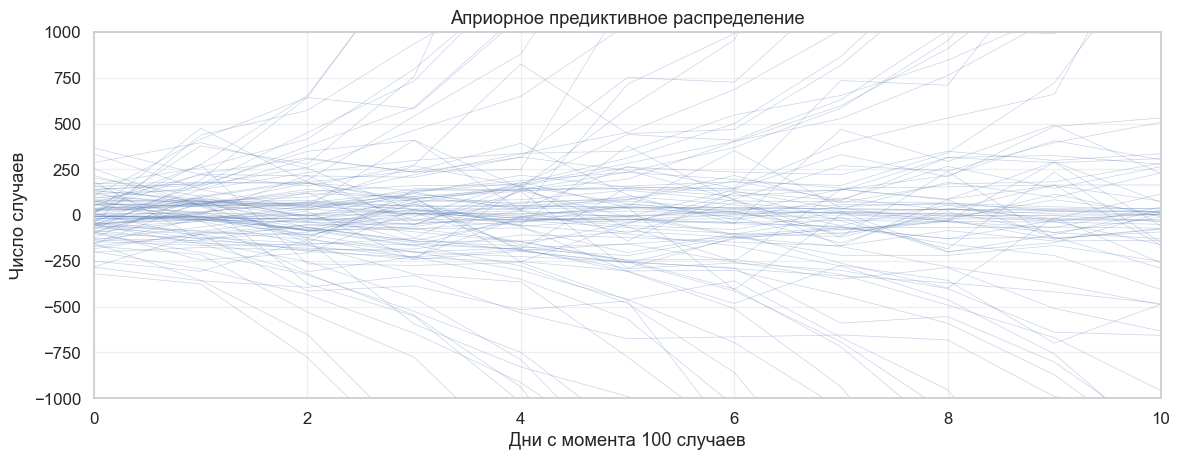

In [8]:
with model_exp1:
    prior_pred = pm.sample_prior_predictive(random_seed=RANDOM_SEED)

plot_paths(prior_pred.prior_predictive['obs'].values.squeeze().T, 'Априорное предиктивное распределение', ylim=(-1000, 1000), xlim=(0, 10))
plt.tight_layout()
plt.show()

Априорная предиктивная проверка выявила несколько проблем:

1. **Отрицательные случаи:** Невозможно в реальности

2. **Начало с нуля:** данные начинаются со 100 случаев

3. **Нормальное правдоподобие:** Допускает отрицательные значения и симметричные ошибки

Это показывает ценность априорной предиктивной проверки.

Давайте улучшим нашу модель. Наличие отрицательных случаев обусловлено использованием нормального распределения правдоподобия. Вместо этого давайте используем отрицательное биномиальное распределение (`NegativeBinomial`), которое похоже на пуассоновское, но имеет дополнительный параметр дисперсии, обеспечивающий большую гибкость в моделировании дисперсии данных.

Мы также изменим априорное распределение свободного члена (intercept), центрировав его на 100, и сузим априорное распределение наклона.

Отрицательное биномиальное распределение использует параметр избыточной дисперсии, который мы опишем с помощью гамма-распределения. В сопутствующем пакете `preliz`, библиотеке для получения априорного распределения, есть удобная утилита `maxent`, которая поможет нам параметризовать это априорное распределение, поскольку гамма-распределение не так интуитивно понятно, как нормальное.

Gamma(alpha=2.22, beta=0.255)


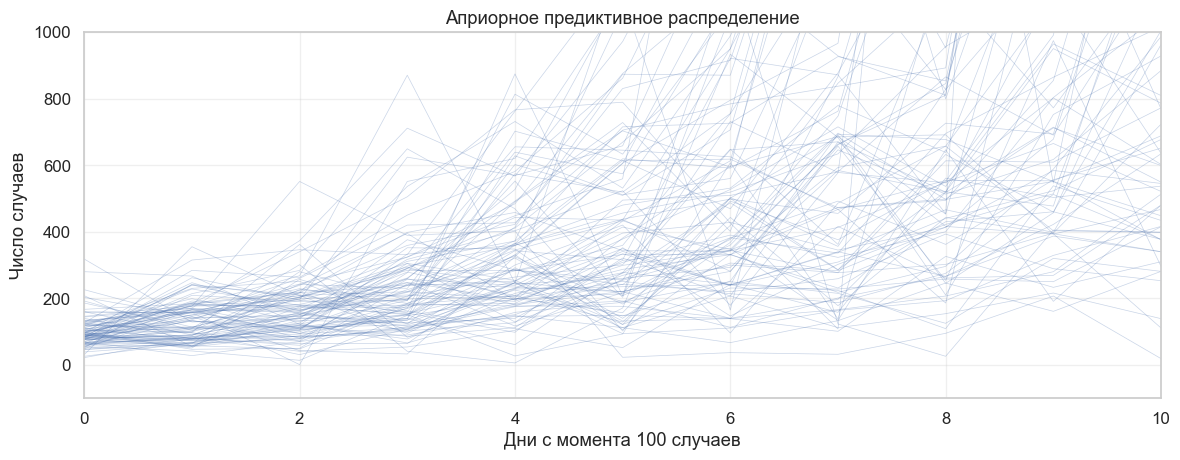

In [9]:
pz.maxent(pz.Gamma(), lower=0.1, upper=20, mass=0.95, plot=False)
alpha_prior = pz.maxent(pz.Gamma(), lower=0.1, upper=20, mass=0.95, plot=False)
print(alpha_prior)

with pm.Model() as model_exp2:
    a = pm.Normal('a', mu=100, sigma=25)
    b = pm.Normal('b', mu=0.3, sigma=0.1)
    growth = exponential_growth(a, b, t)
    alpha_param = pm.Gamma('alpha', alpha=alpha_prior.alpha, beta=alpha_prior.beta)
    pm.NegativeBinomial('obs', growth, alpha=alpha_param, observed=confirmed)
    prior_pred = pm.sample_prior_predictive(random_seed=RANDOM_SEED)

plot_paths(prior_pred.prior_predictive['obs'].values.squeeze().T, 'Априорное предиктивное распределение', ylim=(-100, 1000), xlim=(0, 10))
plt.tight_layout()
plt.show()

Намного лучше! Нет отрицательных случаев, и шкала выглядит более разумной. Но мы всё равно можем включить больше знаний из предметной области.

Мы знаем, что:

* Свободный член не может быть меньше 100 (по построению наших данных)
* Темп роста должен быть положительным

Давайте закодируем это знание: мы используем полунормальное распределение (`HalfNormal`) для свободного члена; то же самое можно применить и для наклона, который, как мы знаем, не будет отрицательным.

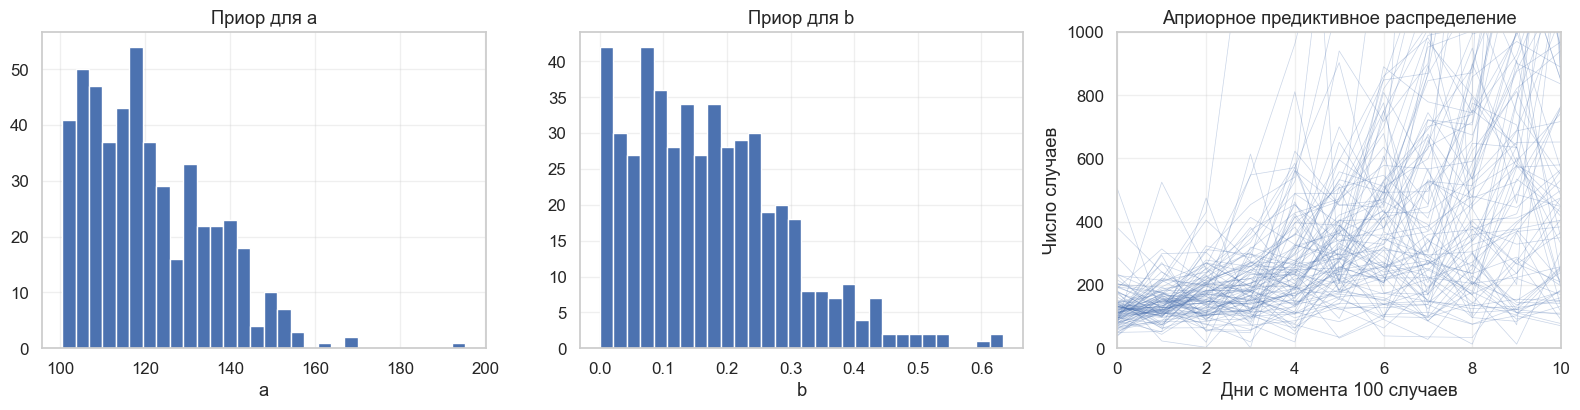

In [10]:
with pm.Model() as model_exp3:
    a0 = pm.HalfNormal('a0', sigma=25)
    a = pm.Deterministic('a', a0 + 100)
    b = pm.HalfNormal('b', sigma=0.2)
    growth = exponential_growth(a, b, t)
    alpha_param = pm.Gamma('alpha', alpha=alpha_prior.alpha, beta=alpha_prior.beta)
    pm.NegativeBinomial('obs', growth, alpha=alpha_param, observed=confirmed)
    prior_pred3 = pm.sample_prior_predictive(random_seed=RANDOM_SEED)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].hist(prior_pred3.prior['a'].values.flatten(), bins=30, color=BLUE)
axes[0].set(title='Приор для a', xlabel='a')
axes[1].hist(prior_pred3.prior['b'].values.flatten(), bins=30, color=BLUE)
axes[1].set(title='Приор для b', xlabel='b')
plot_paths(prior_pred3.prior_predictive['obs'].values.squeeze().T, 'Априорное предиктивное распределение', ylim=(0, 1000), xlim=(0, 10), ax=axes[2])
plt.tight_layout()
plt.show()

#### Шаг 4. Обучение модели

In [11]:
with model_exp3:
    trace_exp3 = pm.sample(**sampler_kwargs)

#### Шаг 5. Проверка сходимости

Прежде чем доверять нашим результатам, мы должны убедиться, что сэмплер сошелся правильно.

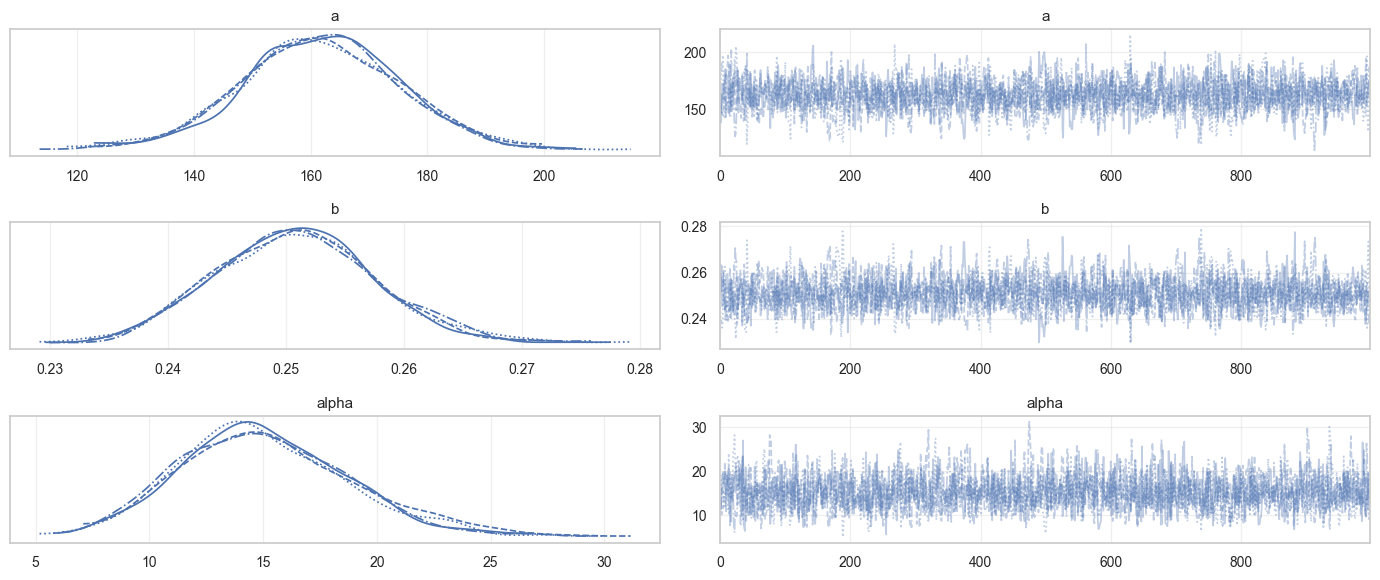

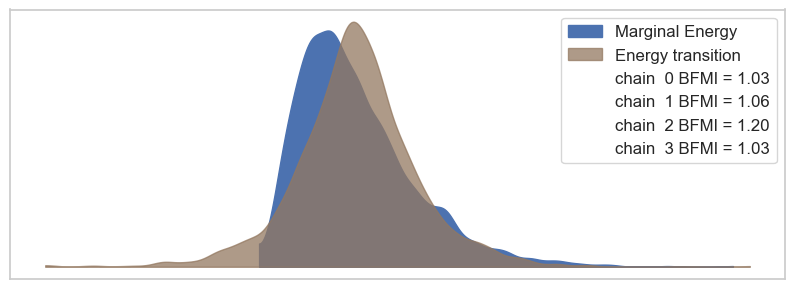

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,161.668,13.569,136.790,187.725,0.337,0.269,1630.0,1538.0,1.0
b,0.251,0.007,0.238,0.264,0.000,0.000,1701.0,1696.0,1.0
alpha,15.124,3.751,7.934,21.870,0.087,0.070,1833.0,1970.0,1.0


In [12]:
az.plot_trace(trace_exp3, var_names=['a', 'b', 'alpha'], figsize=(14, 6))
plt.tight_layout()
plt.show()

az.plot_energy(trace_exp3, figsize=(10, 3.5))
plt.show()

az.summary(trace_exp3, var_names=['a', 'b', 'alpha'])

**Чеклист сходимости**

* Значения R-hat: Все близки к 1,0 (<1,01)
* Эффективный размер выборки: Достаточный для всех параметров (ess_bulk > 400)
* Графики следов: Демонстрируют хорошее смешивание без трендов
* График энергии: Граничные и энергетические распределения хорошо перекрываются

Наша модель успешно сошлась!

#### Сравнение моделей

Давайте быстро сравним две модели, из которых мы получили выборку.

Для сравнения моделей требуются логарифмические правдоподобия соответствующих моделей. Для эффективности они не рассчитываются автоматически, поэтому нам необходимо рассчитать их вручную.

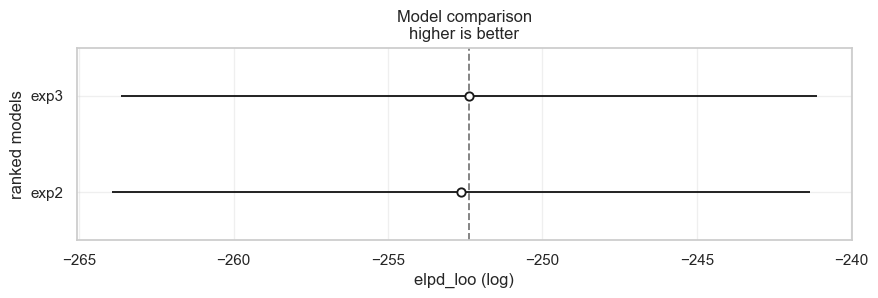

,rank,elpd_loo,se,elpd_diff,dse
exp3,0,-252.39,11.26,0.00,0.00
exp2,1,-252.63,11.30,0.24,0.06


In [13]:
with model_exp2:
    trace_exp2 = pm.sample(**sampler_kwargs, idata_kwargs={'log_likelihood': True})

with model_exp3:
    pm.compute_log_likelihood(trace_exp3, progressbar=False)

comparison = az.compare({'exp2': trace_exp2, 'exp3': trace_exp3})
az.plot_compare(comparison, figsize=(10, 2.5))
plt.show()
comparison[['rank', 'elpd_loo', 'se', 'elpd_diff', 'dse']].round(2)

Ограничение приоров не привело к заметно лучшему соответствию. Это неудивительно, поскольку изменение было незначительным. Мы продолжим использовать `model_exp3`, поскольку знаем, что параметры ограничены именно так.

#### Анализ чувствительности

Важнейший, но часто игнорируемый шаг — это понимание того, насколько наши выводы чувствительны к выбору моделирования.

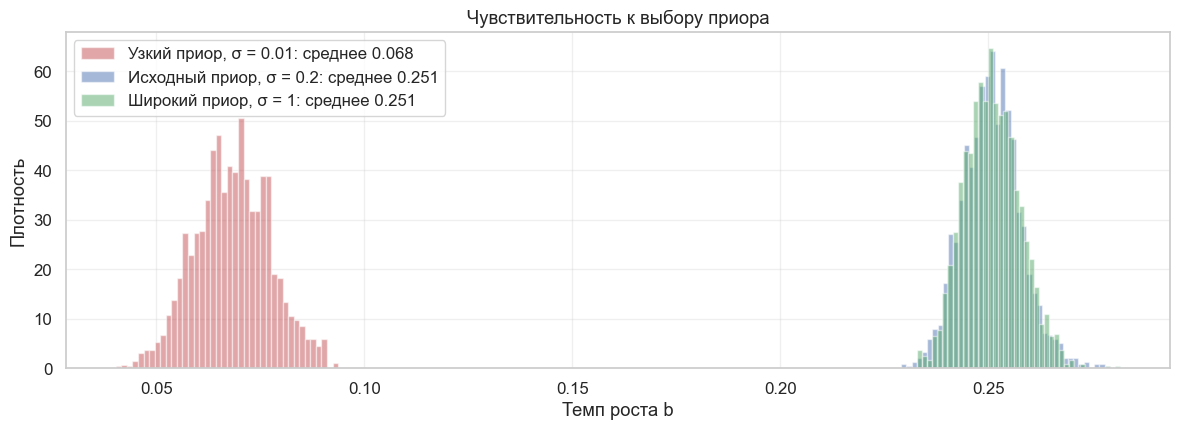

In [14]:
results = {}
for name, b_sigma in [('Узкий приор, σ = 0.01', 0.01), ('Исходный приор, σ = 0.2', 0.2), ('Широкий приор, σ = 1', 1.0)]:
    with pm.Model():
        a0 = pm.HalfNormal('a0', sigma=25)
        a = pm.Deterministic('a', a0 + 100)
        b = pm.HalfNormal('b', sigma=b_sigma)
        alpha_param = pm.Gamma('alpha', alpha=alpha_prior.alpha, beta=alpha_prior.beta)
        pm.NegativeBinomial('obs', exponential_growth(a, b, t), alpha=alpha_param, observed=confirmed)
        results[name] = pm.sample(chains=2, draws=1000, tune=1000, cores=1, random_seed=RANDOM_SEED, progressbar=False)

fig, ax = plt.subplots(figsize=(12, 4.5))
for (name, trace), color in zip(results.items(), [RED, BLUE, GREEN]):
    values = trace.posterior['b'].values.flatten()
    ax.hist(values, bins=40, density=True, color=color, alpha=0.5, label=f'{name}: среднее {values.mean():.3f}')
ax.set(xlabel='Темп роста b', ylabel='Плотность', title='Чувствительность к выбору приора')
ax.legend()
plt.tight_layout()
plt.show()

Широкий приор и исходный дают одно и то же: темп роста 0.251. Данные здесь сильнее приора. Но чрезмерно узкий приор ($\sigma = 0.01$) полностью меняет ответ: 0.068 вместо 0.251. Поэтому «с данными приор не важен» верно только для разумных приоров: приор, противоречащий данным, никуда не исчезает.

Это подчёркивает важность:

* Использования знаний предметной области при выборе приоров
* Проверки чувствительности при ограниченном количестве данных
* Прозрачности в отношении выбранных приоров

#### Шаг 6. Проверка соответствия модели

Подобно априорному прогнозированию, мы также можем генерировать новые данные, многократно извлекая выборки из апостериорного распределения и генерируя данные с использованием этих параметров. Этот процесс называется апостериорной прогностической проверкой и является ключевым этапом валидации байесовской модели.

Апостериорная прогностическая проверка работает следующим образом:

1. Извлекаются выборки параметров из апостериорного распределения (которые у нас уже есть из выборки MCMC).
2. Для каждого набора значений параметров генерируются новые синтетические наборы данных с использованием той же функции правдоподобия, что и в нашей модели.
3. Сравниваются эти синтетические наборы данных с нашими наблюдаемыми данными.

Это позволяет нам оценить, может ли наша модель воспроизводить ключевые особенности наблюдаемых данных. Если апостериорные прогностические выборки сильно отличаются от наших фактических данных, это говорит о том, что наша модель может упускать важные аспекты процесса генерации данных. И наоборот, если апостериорные прогностические выборки хорошо охватывают наши наблюдаемые данные, это свидетельствует о том, что наша модель улавливает основные закономерности в данных.

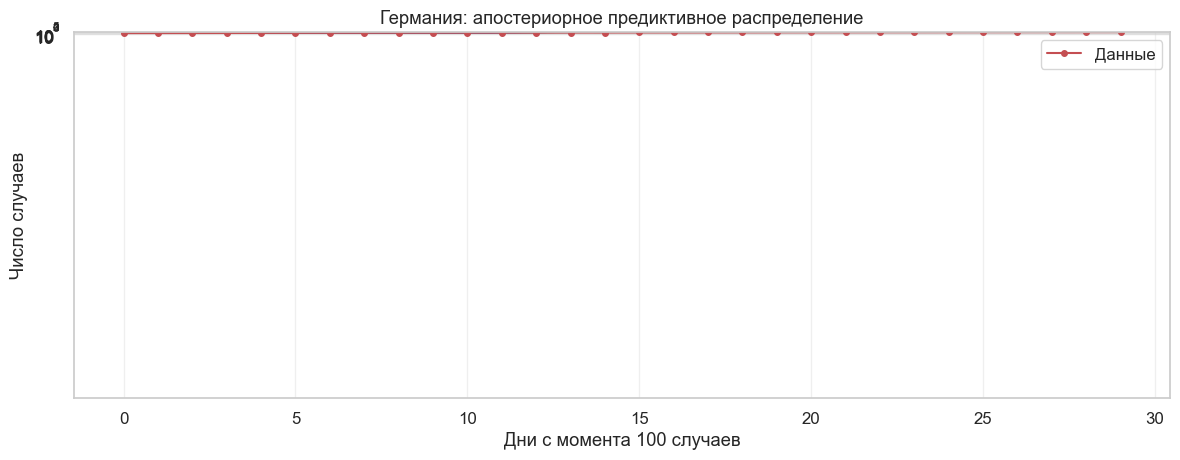

In [15]:
with model_exp3:
    post_pred = pm.sample_posterior_predictive(trace_exp3.posterior, random_seed=RANDOM_SEED, progressbar=False)

post_samples = post_pred.posterior_predictive['obs'].sel(chain=0).values.T
plot_paths(post_samples, 'Германия: апостериорное предиктивное распределение', observed=confirmed, log=True)
plt.tight_layout()
plt.show()

Выглядит неплохо: данные ведут себя как случайные выборки из модели.

В качестве дополнительной проверки мы также можем проверить остатки модели.

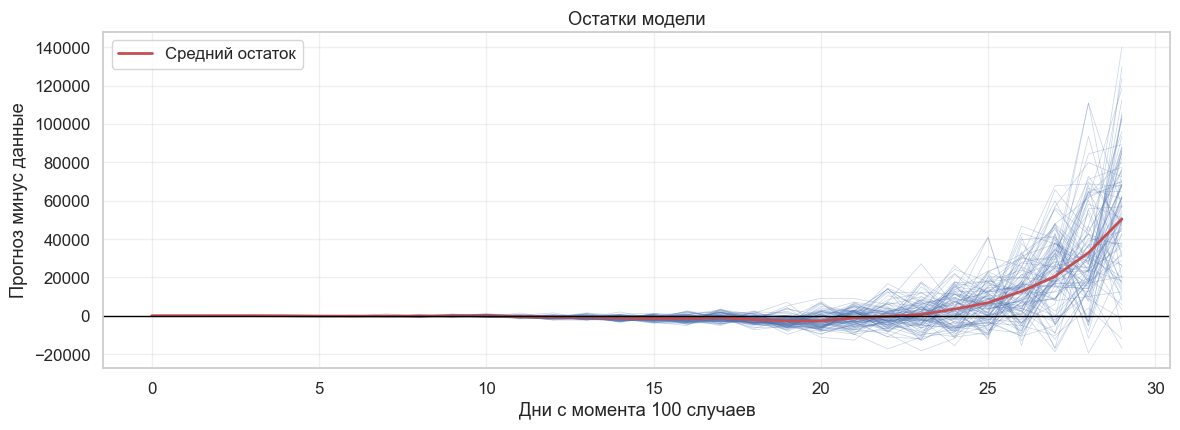

In [16]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(post_samples[:, :100] - confirmed[:, None], color=BLUE, linewidth=0.5, alpha=0.3)
ax.plot(post_samples.mean(axis=1) - confirmed, color=RED, linewidth=2, label='Средний остаток')
ax.axhline(0, color='black', linewidth=1)
ax.set(title='Остатки модели', xlabel='Дни с момента 100 случаев', ylabel='Прогноз минус данные')
ax.legend()
plt.tight_layout()
plt.show()

Обратите внимание на систематическую закономерность в остатках: наблюдается смещение, которое имеет тенденцию к увеличению со временем. Это говорит о том, что наша экспоненциальная модель может быть слишком жесткой для более длительных периодов времени.

#### Прогнозирование

В PyMC прогноз легко сделать с помощью узлов `pm.Data`, в которых можно заменить входные данные после обучения.

Оборачивание входных данных в pm.Data позволяет определить контейнеры данных в модели PyMC, которые можно динамически обновлять после подгонки модели. Это особенно полезно в сценариях прогнозирования, где требуется:

* Обучение на наблюдаемых данных: подгонка модели с использованием доступных обучающих данных

* Переключение на входные данные для прогнозирования: замена обучающих данных новыми входными значениями (например, будущими моментами времени)

* Создание прогнозов: использование апостериорной предиктивной выборки для создания прогнозов на основе подобранной модели

Давайте продемонстрируем этот подход, модифицировав нашу модель экспоненциального роста для использования узлов pm.Data.

In [17]:
with pm.Model() as model_exp4:
    t_data = pm.Data('t', t)
    confirmed_data = pm.Data('confirmed', confirmed)
    a0 = pm.HalfNormal('a0', sigma=25)
    a = pm.Deterministic('a', a0 + 100)
    b = pm.HalfNormal('b', sigma=0.2)
    growth = exponential_growth(a, b, t_data)
    alpha_param = pm.Gamma('alpha', alpha=alpha_prior.alpha, beta=alpha_prior.beta)
    pm.NegativeBinomial('obs', growth, alpha=alpha_param, observed=confirmed_data, shape=t_data.shape)
    trace_exp4 = pm.sample(**sampler_kwargs)

    # При прогнозе наблюдаемые значения не используются, но их форма должна совпадать с новым t
    pm.set_data({'t': np.arange(60), 'confirmed': np.zeros(60, dtype=int)})
    post_pred_forecast = pm.sample_posterior_predictive(trace_exp4.posterior, random_seed=RANDOM_SEED, progressbar=False)

Поскольку мы ранее взяли не все данные, теперь мы можем увидеть, как прогнозы модели соотносятся с оставшейся частью

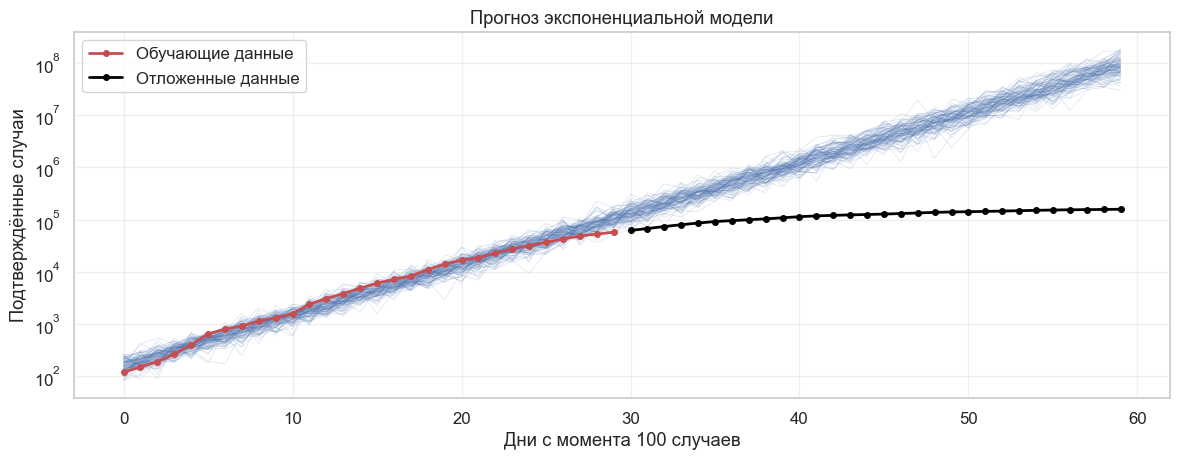

In [18]:
forecast = post_pred_forecast.posterior_predictive['obs'].sel(chain=0).values.T

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(forecast[:, :100], color=BLUE, linewidth=0.5, alpha=0.2)
ax.plot(np.arange(30), confirmed, color=RED, marker='o', markersize=4, linewidth=2, label='Обучающие данные')
ax.plot(np.arange(30, 60), df_full['confirmed'].to_numpy()[30:60], color='black', marker='o', markersize=4, linewidth=2, label='Отложенные данные')
ax.set_yscale('log')
ax.set(title='Прогноз экспоненциальной модели', xlabel='Дни с момента 100 случаев', ylabel='Подтверждённые случаи')
ax.legend()
plt.tight_layout()
plt.show()

Экспоненциальная модель сильно переоценивает число будущих случаев заболевания. Это распространённая проблема экспоненциальных моделей роста: они не учитывают естественные ограничения распространения заболевания.

## Байесовский A/B-тест

Во многом байесовский сеттинг A/B тестирования полностью повторяет обычный частотный, единственные отличия - подходы к определению параметра теста и непосредственно его интерпретация.


**Определение Параметров**

Для байесовского A/B нет единой формулы, связывающей MDE, ошибки и размер выборки, поэтому длительность выбирают симуляцией на исторических или синтетических данных. Для сопряжённой модели с широким приором можно ориентироваться на частотный расчёт, как мы увидим ниже.

**Интерпретация**

В байесовском фреймворке мы получаем совместное постериорное распределение и можем напрямую считать вероятности утверждений. Самый базовый критерий принятия решения выглядит так:
$$
P(\theta_B > \theta_A \mid D) \ge 1 - \alpha
$$

То есть с вероятностью не менее $1 - \alpha$ метрика в тестовой группе выше.

Так же бывает полезно привязать выбранную метрику к чему-нибудь денежному. Например, если мы оценивали конверсии, то можем их подвязать к монетизации:
$$
\text{Monetization} = (\text{Per User Value}) \times (\text{Num Users}) \times \delta- (\text{Implementation Cost})
$$
Таким образом, мы получаем из $p(\delta|X)$ распределение с оценёнными шансами на монетизацию фичи $p(\text{Monetization}|X)$.


Ещё одна популярная метрика — **ожидаемые потери** от выбора группы, её разберём ниже (подробнее можно посмотреть [тут](https://towardsdatascience.com/bayesian-ab-testing-part-i-conversions-ac2635f878ec/) и [тут](https://towardsdatascience.com/bayesian-ab-testing-part-ii-revenue-1fbcf04f96cd/)).

#### Необходимые импорты

### Байесовский A/B на конверсиях

Давайте сначала рассмотрим простой двухвариантный A/B-тест, где интересующей нас метрикой является доля пользователей, совершивших действие (например, покупку хотя бы одного товара), то есть конверсия. Наши варианты обозначены как A и B, где A относится к существующей целевой странице, а B — к новой странице, которую мы хотим протестировать. Результат, который мы хотим получить, — это определить, «лучше» ли B, чем A, что зависит от базовых «истинных» коэффициентов конверсии для каждого варианта. Мы можем сформулировать это следующим образом:

Пусть $\theta_A, \theta_B$ — истинные коэффициенты конверсии для вариантов A и B соответственно. Тогда результат конверсии посетителя в варианте A — случайная величина
$\text{Bernoulli}(\theta_A)$, а $\text{Bernoulli}(\theta_B)$ — для варианта B. Если предположить, что поведение посетителей на целевой странице не зависит от других посетителей (справедливое предположение), то общее количество конверсий
для варианта имеет биномиальное распределение:
$$
y \sim \sum^N \text{Bernoulli}(\theta) = \text{Binomial}(N, \theta)
$$
В байесовской модели мира мы предполагаем, что истинные коэффициенты конверсии $\theta_A, \theta_B$ неизвестны, и вместо этого каждый из них подчиняется бета-распределению. Предполагается, что коэффициенты независимы (мы бы распределили трафик между каждым вариантом случайным образом, чтобы один вариант не влиял на другой):

$$
\theta_A,\ \theta_B \sim \text{Beta}(\alpha, \beta)
$$

Наблюдаемые данные за время A/B-теста (распределение правдоподобия) таковы: количество посетителей, попавших на страницу N, и количество посетителей, купивших хотя бы один товар y:
$$
y_A \sim \text{Binomial}(n=N_A, p=\theta_A), y_B \sim \text{Binomial}(n=N_B, p=\theta_B)
$$
Таким образом, мы можем получить выборку из совместного апостериорного распределения $\theta_A$ и $\theta_B$.

Бета-распределение является сопряжённым априорным распределением для биномиального распределения, поэтому нам не нужна выборка MCMC для оценки апостериорного распределения. Тем не менее мы покажем выборку в PyMC: это упростит расширение модели. Заодно сверим её с точным ответом.

Наконец, помните, что нас интересует результат, лучше ли B, чем A. На практике общепринятой мерой превосходства B является относительное повышение коэффициентов конверсии, т. е. процентная разница $\theta_B$
по сравнению с $\theta_A$:
$$
\text{reluplift}_B = \theta_B/ \theta_A -1
$$

In [19]:
@dataclass
class BetaPrior:
    """Бета-приор для конверсии."""
    alpha: float
    beta: float


@dataclass
class BinomialData:
    """Агрегированные данные биномиального эксперимента."""
    trials: int
    successes: int


class ConversionModel:
    """Байесовская модель A/B-теста на конверсии для произвольного числа вариантов."""

    def __init__(self, priors: BetaPrior) -> None:
        self.priors = priors

    def create_model(self, data: list, comparison_method: str = 'compare_to_control') -> pm.Model:
        """Создаёт PyMC-модель, сравнивая варианты с контролем или с лучшим из остальных."""
        num_variants = len(data)
        trials = [d.trials for d in data]
        successes = [d.successes for d in data]
        with pm.Model() as model:
            p = pm.Beta('p', alpha=self.priors.alpha, beta=self.priors.beta, shape=num_variants)
            pm.Binomial('y', n=trials, p=p, observed=successes, shape=num_variants)
            for i in range(num_variants):
                if comparison_method == 'compare_to_control':
                    comparison = p[0]
                elif comparison_method == 'best_of_rest':
                    others = [p[j] for j in range(num_variants) if j != i]
                    comparison = pmm.maximum(*others) if len(others) > 1 else others[0]
                else:
                    raise ValueError(f'Неизвестный метод: {comparison_method}')
                pm.Deterministic(f'reluplift_{i}', p[i] / comparison - 1)
        return model


def uplift_panel(ax, values, title: str, hdi_prob: float = 0.94) -> None:
    """Рисует гистограмму относительного аплифта с HDI и нулём."""
    values = np.asarray(values).flatten()
    low, high = az.hdi(values, hdi_prob=hdi_prob)
    ax.hist(values, bins=50, color=BLUE, alpha=0.7)
    ax.axvline(0, color=RED, linewidth=1.8)
    ax.axvspan(low, high, color=GREEN, alpha=0.15)
    ax.set_title(f'{title}\nсреднее {values.mean():.2%}, 94% HDI [{low:.2%}; {high:.2%}], P(> 0) = {(values > 0).mean():.3f}', loc='left', fontsize=11)

Теперь выберем приор. Будем считать, что базовая конверсия около 23%, и зададим одинаковый приор для обоих вариантов.

* **Слабый приор** задаётся низкими значениями $\alpha$ и $\beta$. Если $\alpha = 1$, $\beta = 1$, приор равномерен. Если смотреть на одно распределение, это означает, что мы ничего не знаем. Но в A/B-тесте нас интересует относительный прирост, и при слабом приоре его распределение очень широкое: мы неявно говорим, что варианты могут сильно различаться.
* **Сильный приор** задаётся высокими значениями $\alpha$, $\beta$ и подразумевает, что варианты не сильно отличаются друг от друга.

Важно, чтобы приор был центрирован на реальном уровне метрики: приор вроде $\text{Beta}(5000, 5000)$ при конверсии 10% сдвигает оценки обоих вариантов к 50% и сжимает относительный эффект. Проиллюстрируем силу приора априорными предиктивными проверками.

#### Смотрим на разные приоры

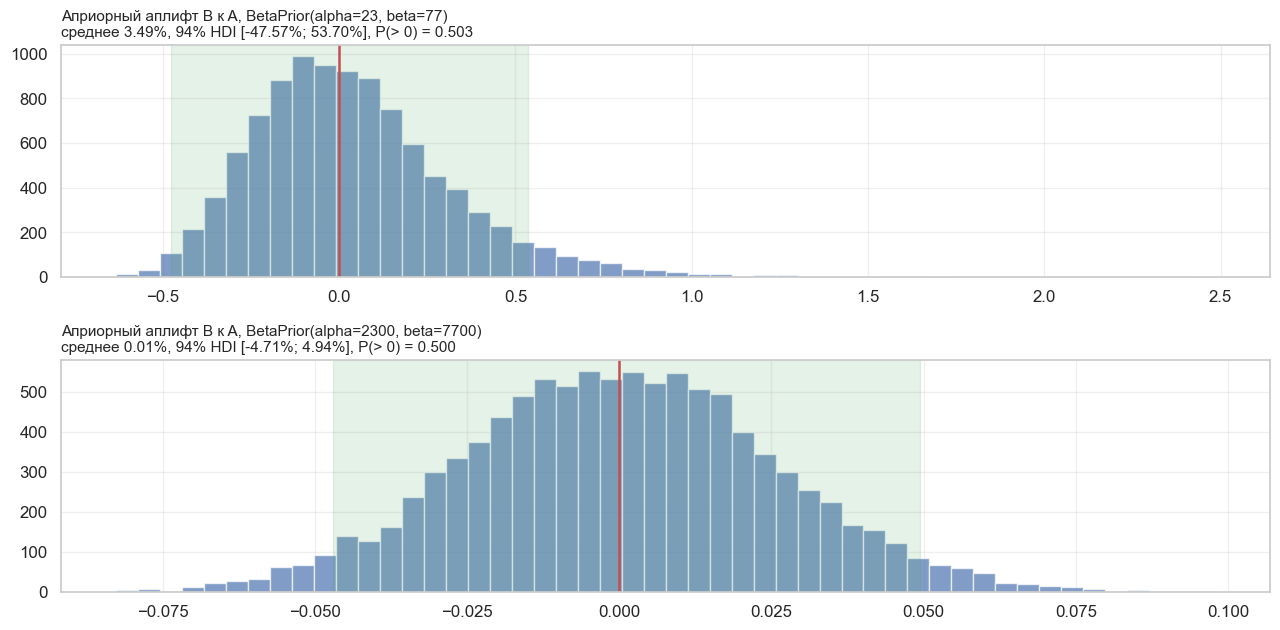

In [20]:
weak_prior = BetaPrior(alpha=23, beta=77)
strong_prior = BetaPrior(alpha=2300, beta=7700)
empty_data = [BinomialData(1, 1), BinomialData(1, 1)]

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
for ax, prior in zip(axes, [weak_prior, strong_prior]):
    with ConversionModel(prior).create_model(empty_data):
        predictive = pm.sample_prior_predictive(draws=10_000, random_seed=RANDOM_SEED)
    uplift_panel(ax, predictive.prior['reluplift_1'].values, f'Априорный аплифт B к A, {prior}')
plt.tight_layout()
plt.show()

При слабом приоре 94% HDI для относительного аплифта B к A составляет примерно [−48%, +54%], а при сильном примерно [−5%, +5%]. Это «отправная точка» для распределения аплифта, и она влияет на то, как конверсии переходят в постериор.

На практике выбор приора зависит от контекста компании. Сильный приор страхует от случайно больших оценок на малых данных, но сжимает реальные эффекты к нулю и требует больше данных. Слабый приор даёт больший вес наблюдаемым данным.

Ниже посмотрим на результат при двух приорах.

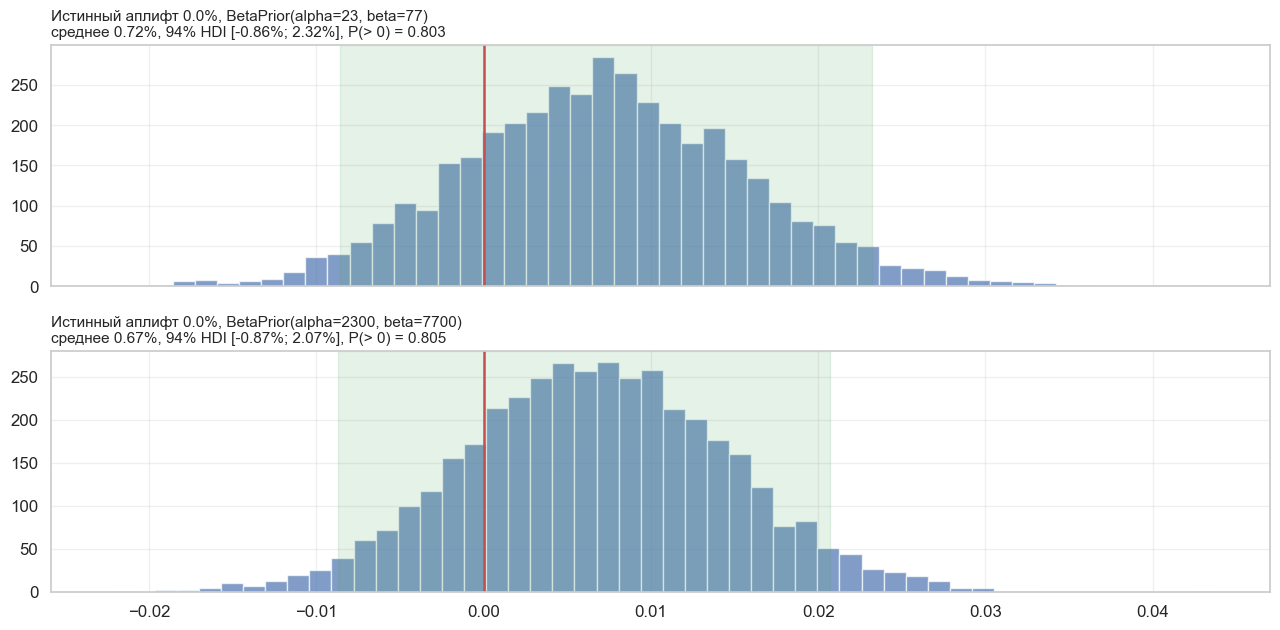

In [21]:
def generate_binomial_data(true_rates: list, samples_per_variant: int, rng: np.random.Generator) -> list:
    """Генерирует агрегированные биномиальные данные для вариантов."""
    return [BinomialData(samples_per_variant, int(rng.binomial(samples_per_variant, rate))) for rate in true_rates]


def fit_two_priors(true_rates: list, samples_per_variant: int = 100_000) -> dict:
    """Обучает модель на одних данных с двумя приорами и рисует аплифт."""
    data = generate_binomial_data(true_rates, samples_per_variant, rng)
    fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
    traces = {}
    for ax, prior in zip(axes, [weak_prior, strong_prior]):
        with ConversionModel(prior).create_model(data):
            traces[str(prior)] = pm.sample(chains=2, cores=1, draws=2000, tune=1000, random_seed=RANDOM_SEED, progressbar=False)
        uplift_panel(ax, traces[str(prior)].posterior['reluplift_1'].values, f'Истинный аплифт {true_rates[1] / true_rates[0] - 1:.1%}, {prior}')
    plt.tight_layout()
    plt.show()
    return {'data': data, 'traces': traces}


aa_fit = fit_two_priors([0.23, 0.23])

* В обоих случаях истинный аплифт 0% лежит в пределах 94% HDI: примерно [−0.9%, +2.3%] при слабом приоре и [−0.9%, +2.1%] при сильном.
* Затем можно принять решение о запуске варианта B. Например, катить вариант, если 94% HDI выше 0. Здесь HDI включает 0, поэтому решение — не катить.
* При $n = 100\,000$ данные намного сильнее приора, поэтому оба приора дают почти одинаковый ответ.

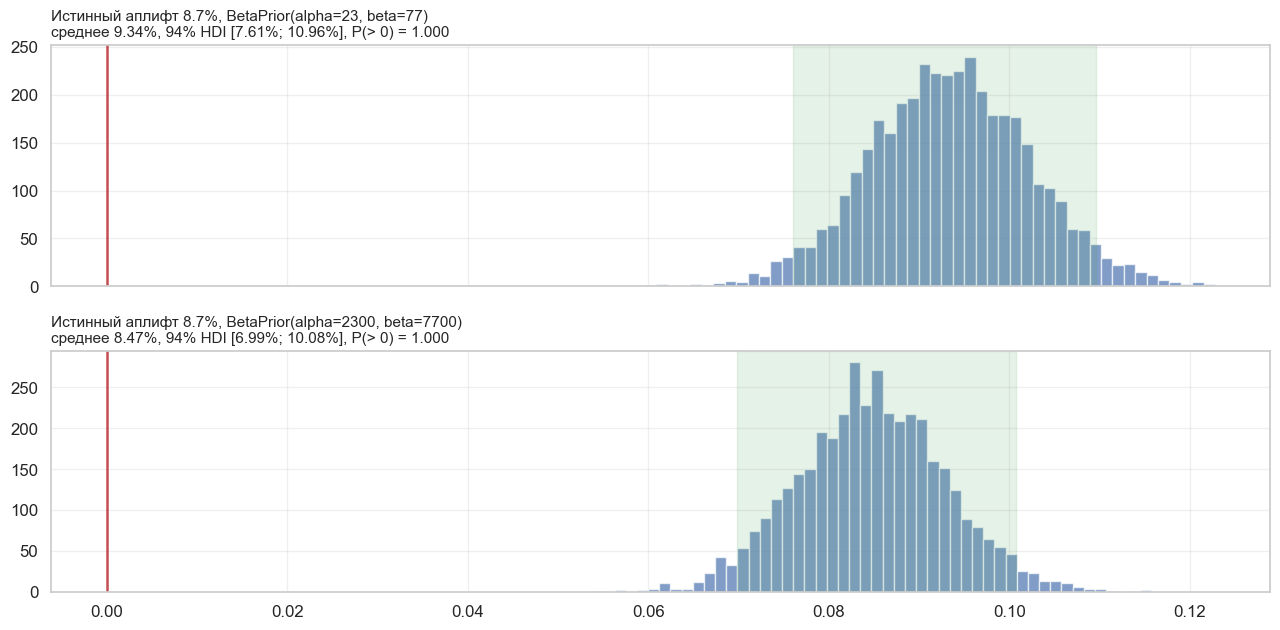

In [22]:
real_fit = fit_two_priors([0.23, 0.25])

В обоих случаях 94% HDI значительно выше 0, и решением было бы внедрить вариант B: это истинное открытие. Заметно влияние приора: при истинном аплифте 8.7% слабый приор даёт оценку 9.3%, а сильный 8.5%, потому что сжимает эффект к нулю.

**Проверка MCMC точной формулой и связь с p-value**

Для бета-приоров вероятность $P(\theta_B > \theta_A)$ можно посчитать точно (формула есть у [Эвана Миллера](https://www.evanmiller.org/bayesian-ab-testing.html)). Сравним её с MCMC и с односторонним p-value z-теста на одних данных.

In [23]:
def prob_b_beats_a_exact(alpha_a: int, beta_a: int, alpha_b: int, beta_b: int) -> float:
    """Точно считает P(B > A) для независимых бета-распределений с целыми параметрами B."""
    i = np.arange(alpha_b)
    terms = betaln(alpha_a + i, beta_a + beta_b) - np.log(beta_b + i) - betaln(1 + i, beta_b) - betaln(alpha_a, beta_a)
    return float(np.exp(terms).sum())


def one_sided_pvalue(a: BinomialData, b: BinomialData) -> float:
    """Считает односторонний p-value z-теста для H1: B лучше A."""
    p_a, p_b = a.successes / a.trials, b.successes / b.trials
    pooled = (a.successes + b.successes) / (a.trials + b.trials)
    z = (p_b - p_a) / np.sqrt(pooled * (1 - pooled) * (1 / a.trials + 1 / b.trials))
    return float(stats.norm.sf(z))


prior = BetaPrior(1, 1)
rows = []
check_rng = np.random.default_rng(1)
for rates, n in [([0.10, 0.10], 2000), ([0.10, 0.11], 3000), ([0.10, 0.115], 4000), ([0.23, 0.235], 8000)]:
    a, b = generate_binomial_data(rates, n, check_rng)
    exact = prob_b_beats_a_exact(prior.alpha + a.successes, prior.beta + a.trials - a.successes,
                                 prior.alpha + b.successes, prior.beta + b.trials - b.successes)
    with ConversionModel(prior).create_model([a, b]):
        trace = pm.sample(chains=2, cores=1, draws=2000, tune=1000, random_seed=RANDOM_SEED, progressbar=False)
    rows.append({'Конверсии': f'{a.successes / n:.3f} / {b.successes / n:.3f}', 'P(B > A), формула': exact,
                 'P(B > A), MCMC': float((trace.posterior['reluplift_1'].values > 0).mean()), '1 - p-value': 1 - one_sided_pvalue(a, b)})

pd.DataFrame(rows).set_index('Конверсии').round(3)

,"P(B > A), формула","P(B > A), MCMC",1 - p-value
Конверсии,,,
0.098 / 0.091,0.225,0.217,0.225
0.100 / 0.112,0.934,0.928,0.934
0.107 / 0.110,0.640,0.631,0.640
0.227 / 0.235,0.885,0.896,0.885


MCMC совпадает с точной формулой с точностью до шума сэмплирования. Но главное в другом: при плоском приоре $P(B > A)$ практически равно $1 - p$ одностороннего теста, совпадение здесь до третьего знака. Значит, правило $P(B > A) > 0.95$ при плоском приоре — это тот же односторонний тест с $\alpha = 5\%$, что соответствует двустороннему тесту с $\alpha = 10\%$. Разница между подходами здесь в интерпретации, а не в решении.

**Подглядывание: два разных вопроса**

Часто говорят, что байесовский тест можно смотреть в любой момент. Проверим это на двух вопросах с правилом «останавливаемся, как только $P(B > A) > 0.95$»:

1. **Вопрос про A/A.** Если эффекта нет совсем, как часто мы ошибочно запустим вариант?
2. **Вопрос про откалиброванность.** Если реальные эффекты случайны, какая доля запусков окажется действительно лучше контроля? Сравним анализ с верным приором на разность (он совпадает с тем, как устроены эффекты) и с плоским приором $\text{Beta}(1, 1)$.

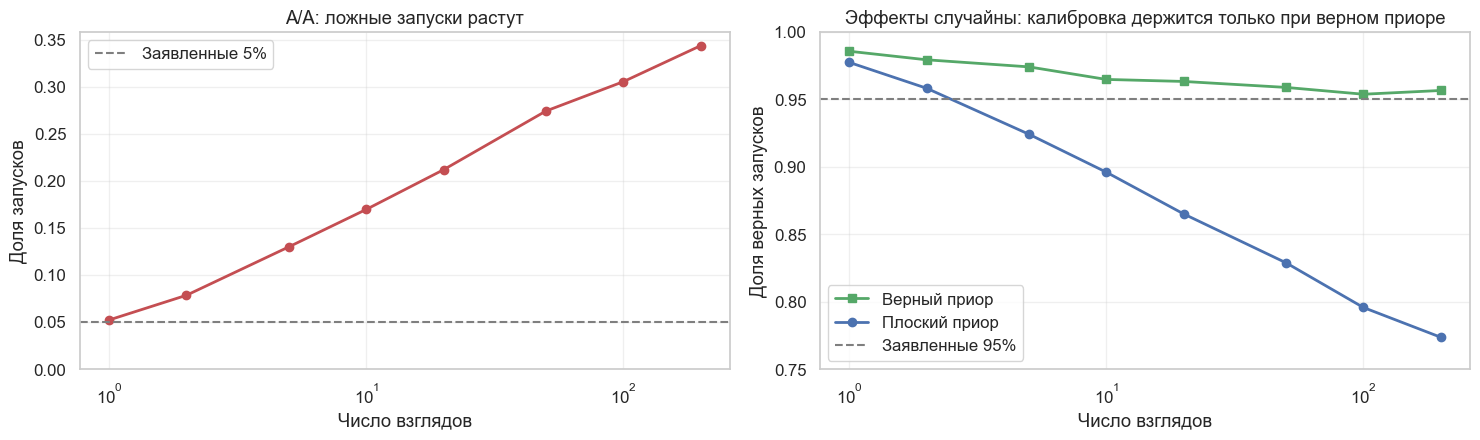

,Запуски на A/A,Верных при плоском приоре,Верных при верном приоре
Взглядов,,,
1,0.052,0.977,0.986
2,0.079,0.958,0.979
5,0.130,0.924,0.974
10,0.170,0.896,0.965
20,0.212,0.865,0.963
50,0.274,0.829,0.959
100,0.306,0.796,0.954
200,0.344,0.774,0.957


In [24]:
def prob_b_better(successes_a: np.ndarray, successes_b: np.ndarray, n: np.ndarray, a0: float = 1, b0: float = 1) -> np.ndarray:
    """Приближённо считает P(B > A) для бета-постериоров через нормальное приближение."""
    total = a0 + b0 + n
    mean_a, mean_b = (a0 + successes_a) / total, (a0 + successes_b) / total
    variance = (mean_a * (1 - mean_a) + mean_b * (1 - mean_b)) / (total + 1)
    return stats.norm.cdf((mean_b - mean_a) / np.sqrt(variance))


def peeking_study(looks_count: int, n_max: int = 20_000, base: float = 0.10, prior_std: float = 0.005, n_sims: int = 40_000, seed: int = 5) -> dict:
    """Сравнивает ложные запуски на A/A и долю верных запусков при эффектах из приора."""
    rng = np.random.default_rng(seed)
    n = np.round(np.linspace(n_max / looks_count, n_max, looks_count))
    gaps = np.diff(n, prepend=0).astype(int)

    a = np.cumsum(rng.binomial(gaps, base, size=(n_sims, looks_count)), axis=1)
    b = np.cumsum(rng.binomial(gaps, base, size=(n_sims, looks_count)), axis=1)
    aa_rate = (prob_b_better(a, b, n) > 0.95).any(axis=1).mean()

    effects = rng.normal(0, prior_std, n_sims)
    a = np.cumsum(rng.binomial(gaps, base, size=(n_sims, looks_count)), axis=1)
    b = np.cumsum(rng.binomial(gaps, np.clip(base + effects, 0, 1)[:, None], size=(n_sims, looks_count)), axis=1)

    # Плоский приор Beta(1, 1): реальные эффекты намного меньше, чем он допускает
    launched_flat = (prob_b_better(a, b, n) > 0.95).any(axis=1)

    # Верный приор на разность: N(0, prior_std^2), постериор разности тоже нормальный
    difference, variance = (b - a) / n, 2 * base * (1 - base) / n
    post_variance = 1 / (1 / prior_std ** 2 + 1 / variance)
    post_mean = post_variance * difference / variance
    launched_true = (stats.norm.cdf(post_mean / np.sqrt(post_variance)) > 0.95).any(axis=1)

    return {'Взглядов': looks_count, 'Запуски на A/A': aa_rate, 'Верных при плоском приоре': (effects[launched_flat] > 0).mean(),
            'Верных при верном приоре': (effects[launched_true] > 0).mean()}


peeking = pd.DataFrame([peeking_study(k) for k in [1, 2, 5, 10, 20, 50, 100, 200]]).set_index('Взглядов')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].plot(peeking.index, peeking['Запуски на A/A'], color=RED, marker='o', linewidth=2)
axes[0].axhline(0.05, color=GRAY, linestyle='--', linewidth=1.5, label='Заявленные 5%')
axes[0].set_xscale('log')
axes[0].set(xlabel='Число взглядов', ylabel='Доля запусков', title='A/A: ложные запуски растут', ylim=(0, None))
axes[0].legend()
axes[1].plot(peeking.index, peeking['Верных при верном приоре'], color=GREEN, marker='s', linewidth=2, label='Верный приор')
axes[1].plot(peeking.index, peeking['Верных при плоском приоре'], color=BLUE, marker='o', linewidth=2, label='Плоский приор')
axes[1].axhline(0.95, color=GRAY, linestyle='--', linewidth=1.5, label='Заявленные 95%')
axes[1].set_xscale('log')
axes[1].set(xlabel='Число взглядов', ylabel='Доля верных запусков', title='Эффекты случайны: калибровка держится только при верном приоре', ylim=(0.75, 1))
axes[1].legend()
plt.tight_layout()
plt.show()

peeking.round(3)

Ответ состоит из двух частей:

* **На A/A ошибка растёт.** При одном взгляде ложных запусков 5.2%, при 10 взглядах 17%, при 200 взглядах 34%. Это та же инфляция, что и у обычного теста с подглядыванием.
* **С верным приором вероятность откалибрована.** Если приор совпадает с тем, как устроены реальные эффекты, доля верных запусков держится на 95–99% при любом числе взглядов. Постериор действительно не зависит от правила остановки.
* **С неверным приором калибровки нет.** Плоский приор допускает намного большие эффекты, чем есть на самом деле, и доля верных запусков падает с 98% до 77%.

Иными словами, байесовская гарантия звучит так: «если приор верен, то вероятность верна при любой остановке». Она не обещает контроль ошибки первого рода, и она ровно настолько надёжна, насколько верен приор. На практике точечный нулевой эффект встречается часто, а обычные приоры его не содержат.

**Ожидаемые потери**

Вероятность $P(B > A)$ не учитывает размер ошибки: мы можем быть на 95% уверены в варианте, но в оставшихся 5% случаев потерять много. **Ожидаемые потери** от выбора варианта $B$ учитывают это:

$$
L(B) = \mathbb{E}\big[\max(\theta_A - \theta_B,\ 0) \mid D\big]
$$

Вариант запускают, если потери ниже порога безразличия $\varepsilon$, например 0.01% конверсии. Посчитаем это по выборке из постериора, MCMC здесь не нужен.

In [25]:
def expected_loss(a: BinomialData, b: BinomialData, prior: BetaPrior, draws: int = 500_000, seed: int = 1) -> dict:
    """Считает P(B > A) и ожидаемые потери выбора каждого варианта по выборке из постериора."""
    rng = np.random.default_rng(seed)
    theta_a = rng.beta(prior.alpha + a.successes, prior.beta + a.trials - a.successes, draws)
    theta_b = rng.beta(prior.alpha + b.successes, prior.beta + b.trials - b.successes, draws)
    return {'P(B > A)': (theta_b > theta_a).mean(), 'Потери при выборе B': np.maximum(theta_a - theta_b, 0).mean(),
            'Потери при выборе A': np.maximum(theta_b - theta_a, 0).mean()}


pd.DataFrame({
    'Мало данных: 110 из 1000 и 125 из 1000': expected_loss(BinomialData(1000, 110), BinomialData(1000, 125), BetaPrior(10, 90)),
    'Много данных: 11000 из 100000 и 11250 из 100000': expected_loss(BinomialData(100_000, 11_000), BinomialData(100_000, 11_250), BetaPrior(10, 90)),
}).T.round(5)

,P(B > A),Потери при выборе B,Потери при выборе A
Мало данных: 110 из 1000 и 125 из 1000,0.84235,0.00113,0.01479
Много данных: 11000 из 100000 и 11250 из 100000,0.96238,0.00002,0.00252


Метрики ведут себя по-разному. При малых данных $P(B > A) = 0.84$, а потери выбора B составляют 0.11% конверсии. При больших данных $P(B > A) = 0.96$, а потери упали до 0.002%. При пороге $\varepsilon = 0.01\%$ в первом случае запускать рано, а во втором можно.

### Байесовский A/B на выручке

А что, если мы хотим сравнить варианты A/B-тестирования с точки зрения генерируемого ими дохода и/или оценить, какой дополнительный доход приносит выигрышный вариант? Мы не можем использовать для этого бета-биномиальную модель, поскольку возможные значения теперь лежат на $[0, \infty)$. Пусть модель выглядит следующим образом:

Доход от посетителя равен произведению индикатора покупки на сумму покупки:
$$
\text{Revenue}_{i} = \text{Bernoulli}(\theta)_i \times \text{Exponential}(\lambda)_{i}
$$

Мы предполагаем, что вероятность оплаты не зависит от средней суммы, потраченной при оплате. Это типичное предположение на практике, если только у нас нет оснований полагать, что эти два параметра имеют взаимозависимость. Таким образом, мы можем создать отдельные модели для общего числа посетителей, совершающих покупки, и общей суммы, потраченной посетителями, совершающими покупки (предполагая независимость поведения каждого посетителя):
$$
c \sim \sum^N\text{Bernoulli}(\theta) = \text{Binomial}(N, \theta)
$$
$$
r \sim \sum^K\text{Exponential}(\lambda) = \text{Gamma}(K, \lambda)
$$

где
$N$ — общее число посетителей,
$K$ — общее число посетителей, совершивших хотя бы одну покупку.

Мы можем повторно использовать нашу бета-биномиальную модель, разработанную ранее, для моделирования конверсий. Для параметра $\lambda$ мы используем гамма-распределение: оно сопряжено с показательным распределением. Обратите внимание, что $\lambda$ — это обратная величина к среднему чеку: при среднем чеке 10 приор должен быть сосредоточен около 0.1. Таким образом, сетап выглядит следующим образом:
$$
\theta_A,\ \theta_B \sim \text{Beta}(\alpha_1, \beta_1) \\
\lambda_A,\ \lambda_B \sim \text{Gamma}(\alpha_2, \beta_2) \\
c_A \sim \text{Binomial}(N_A, \theta_A), c_B \sim \text{Binomial}(N_B, \theta_B) \\
r_A \sim \text{Gamma}(c_A, \lambda_A), r_B \sim \text{Gamma}(c_B, \lambda_B) \\
\mu_A = \theta_A \times \frac{1}{\lambda_A}, \mu_B = \theta_B \times \frac{1}{\lambda_B} \\
\text{reluplift}_B =\mu_B/\mu_A -1
$$

Здесь  $\mu$ представляет средний доход на пользователя, включая тех, кто не совершил покупку. Это лучший способ оценить общий эффект от выручки — некоторые варианты могут увеличить средний объём продаж, но уменьшить долю посетителей, которые вообще платят (например, если мы продвигали более дорогие товары на целевой странице).

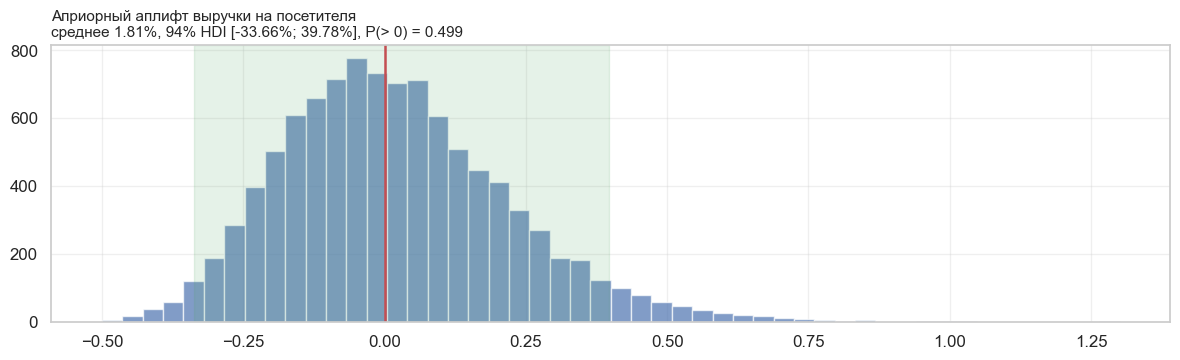

In [26]:
@dataclass
class GammaPrior:
    """Гамма-приор для параметра λ, обратного среднему чеку."""
    alpha: float
    beta: float


@dataclass
class RevenueData:
    """Агрегированные данные по выручке варианта."""
    visitors: int
    purchased: int
    total_revenue: float


class RevenueModel:
    """Байесовская модель A/B-теста по выручке на посетителя."""

    def __init__(self, conversion_rate_prior: BetaPrior, mean_purchase_prior: GammaPrior) -> None:
        self.conversion_rate_prior = conversion_rate_prior
        self.mean_purchase_prior = mean_purchase_prior

    def create_model(self, data: list) -> pm.Model:
        """Создаёт PyMC-модель выручки: сравнение варианта с лучшим из остальных."""
        num_variants = len(data)
        visitors = [d.visitors for d in data]
        purchased = [d.purchased for d in data]
        total_revenue = [d.total_revenue for d in data]

        with pm.Model() as model:
            theta = pm.Beta('theta', alpha=self.conversion_rate_prior.alpha, beta=self.conversion_rate_prior.beta, shape=num_variants)
            lam = pm.Gamma('lam', alpha=self.mean_purchase_prior.alpha, beta=self.mean_purchase_prior.beta, shape=num_variants)
            pm.Binomial('converted', n=visitors, p=theta, observed=purchased, shape=num_variants)
            pm.Gamma('revenue', alpha=purchased, beta=lam, observed=total_revenue, shape=num_variants)
            revenue_per_visitor = pm.Deterministic('revenue_per_visitor', theta / lam)

            for i in range(num_variants):
                others = [j for j in range(num_variants) if j != i]
                best = (lambda values: pmm.maximum(*values) if len(values) > 1 else values[0])
                pm.Deterministic(f'theta_reluplift_{i}', theta[i] / best([theta[j] for j in others]) - 1)
                pm.Deterministic(f'mean_purchase_reluplift_{i}', (1 / lam[i]) / best([1 / lam[j] for j in others]) - 1)
                pm.Deterministic(f'reluplift_{i}', revenue_per_visitor[i] / best([revenue_per_visitor[j] for j in others]) - 1)
        return model


conversion_prior = BetaPrior(alpha=100, beta=900)     # конверсия около 10%
purchase_prior = GammaPrior(alpha=100, beta=1000)     # λ около 0.1, то есть средний чек около 10

with RevenueModel(conversion_prior, purchase_prior).create_model([RevenueData(10_000, 1000, 10_000.0), RevenueData(10_000, 1000, 10_000.0)]):
    revenue_prior_predictive = pm.sample_prior_predictive(draws=10_000, random_seed=RANDOM_SEED)

fig, ax = plt.subplots(figsize=(12, 3.8))
uplift_panel(ax, revenue_prior_predictive.prior['reluplift_1'].values, 'Априорный аплифт выручки на посетителя')
plt.tight_layout()
plt.show()

Как и в модели для конверсий, ширина априорного распределения аплифта зависит от силы приоров.

Далее мы сгенерируем синтетические данные для модели. Мы сгенерируем следующие сценарии:

* Одинаковая склонность к покупке и одинаковая средняя стоимость покупки.

* Более низкая склонность к покупке и более высокая средняя стоимость покупки, но общий доход на посетителя тот же.

* Более высокая склонность к покупке и более высокая средняя стоимость покупки, а также общий более высокий доход на посетителя.

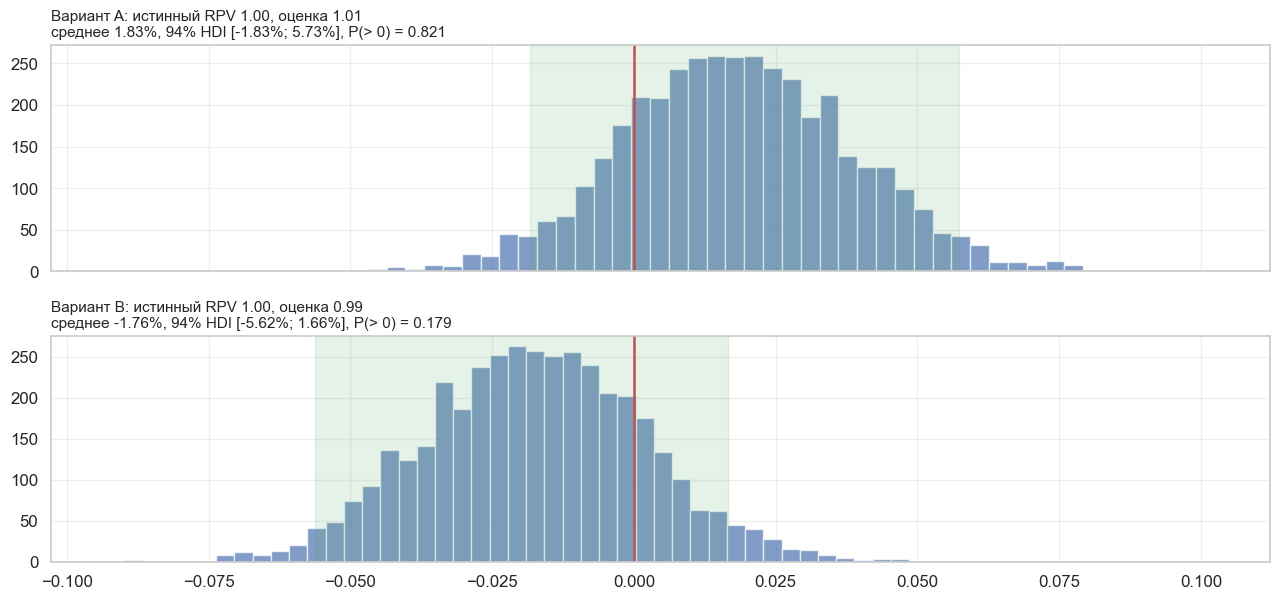

In [27]:
def generate_revenue_data(conversion_rates: list, mean_purchase: list, samples_per_variant: int, rng: np.random.Generator) -> list:
    """Генерирует агрегированные данные: покупки и сумму показательных чеков."""
    data = []
    for rate, mean in zip(conversion_rates, mean_purchase):
        purchased = int(rng.binomial(samples_per_variant, rate))
        data.append(RevenueData(samples_per_variant, purchased, float(rng.gamma(purchased, mean))))
    return data


def run_revenue_scenario(conversion_rates: list, mean_purchase: list, samples_per_variant: int = 100_000):
    """Запускает сценарий A/B-теста по выручке и рисует аплифт."""
    data = generate_revenue_data(conversion_rates, mean_purchase, samples_per_variant, rng)
    with RevenueModel(conversion_prior, purchase_prior).create_model(data):
        trace = pm.sample(chains=2, cores=1, draws=2000, tune=1000, random_seed=RANDOM_SEED, progressbar=False, target_accept=0.9)

    fig, axes = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True)
    for i, (ax, variant) in enumerate(zip(axes, 'AB')):
        true_rpv = conversion_rates[i] * mean_purchase[i]
        estimated = trace.posterior['revenue_per_visitor'].values[..., i].mean()
        uplift_panel(ax, trace.posterior[f'reluplift_{i}'].values, f'Вариант {variant}: истинный RPV {true_rpv:.2f}, оценка {estimated:.2f}')
    plt.tight_layout()
    plt.show()
    return trace


# Одинаковая склонность к покупке и одинаковая средняя стоимость покупки
_ = run_revenue_scenario([0.1, 0.1], [10, 10])

___

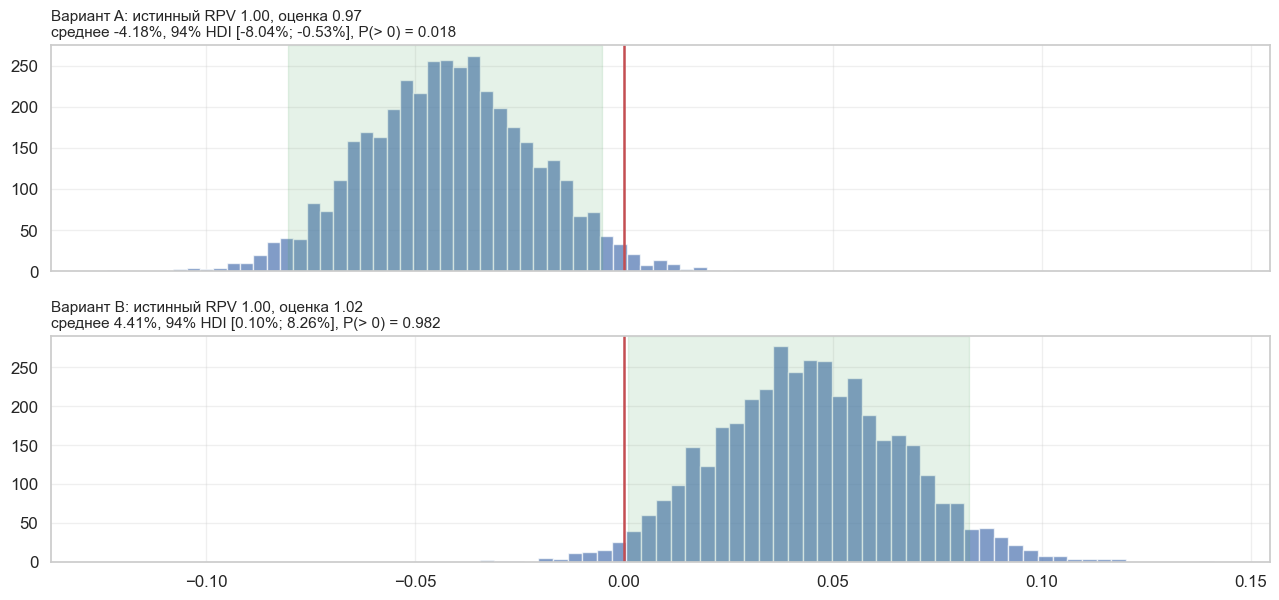

In [28]:
# Более низкая склонность к покупке и более высокая средняя стоимость покупки, доход на посетителя тот же
scenario_value_2 = run_revenue_scenario([0.1, 0.08], [10, 12.5])

* Истинный RPV здесь одинаков, но в этом запуске 94% HDI для B лежит чуть выше 0: аплифт 4.4%, $P(> 0) = 0.98$. Это ложный сигнал, а не ошибка модели. Выручка шумит сильнее конверсии, и даже правильная модель иногда ошибается, поэтому один запуск ничего не доказывает.

* В этих случаях также полезно построить графики относительного распределения прироста для доли покупок и средней стоимости покупки, чтобы понять, как A/B-тестирование повлияло на поведение посетителей. Мы покажем это ниже:

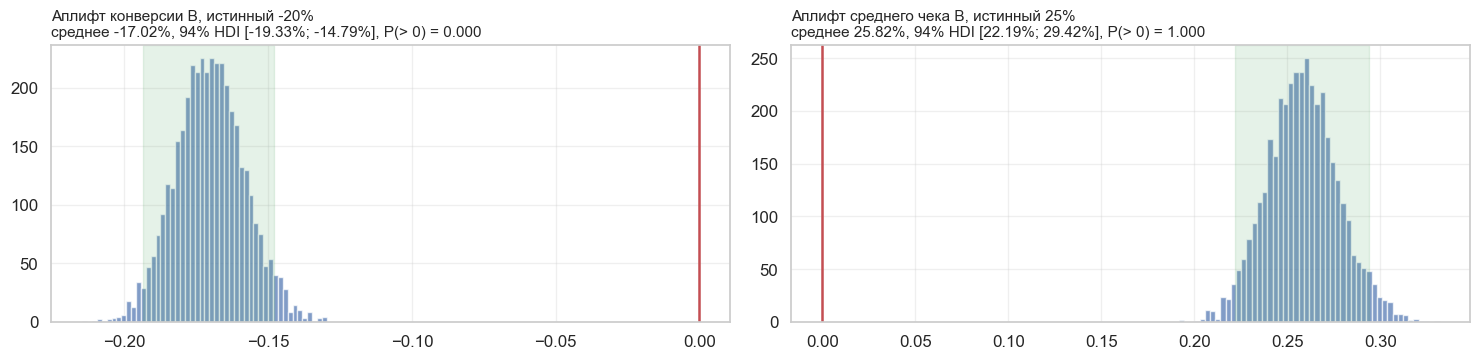

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
uplift_panel(axes[0], scenario_value_2.posterior['theta_reluplift_1'].values, f'Аплифт конверсии B, истинный {0.08 / 0.10 - 1:.0%}')
uplift_panel(axes[1], scenario_value_2.posterior['mean_purchase_reluplift_1'].values, f'Аплифт среднего чека B, истинный {12.5 / 10 - 1:.0%}')
plt.tight_layout()
plt.show()

___

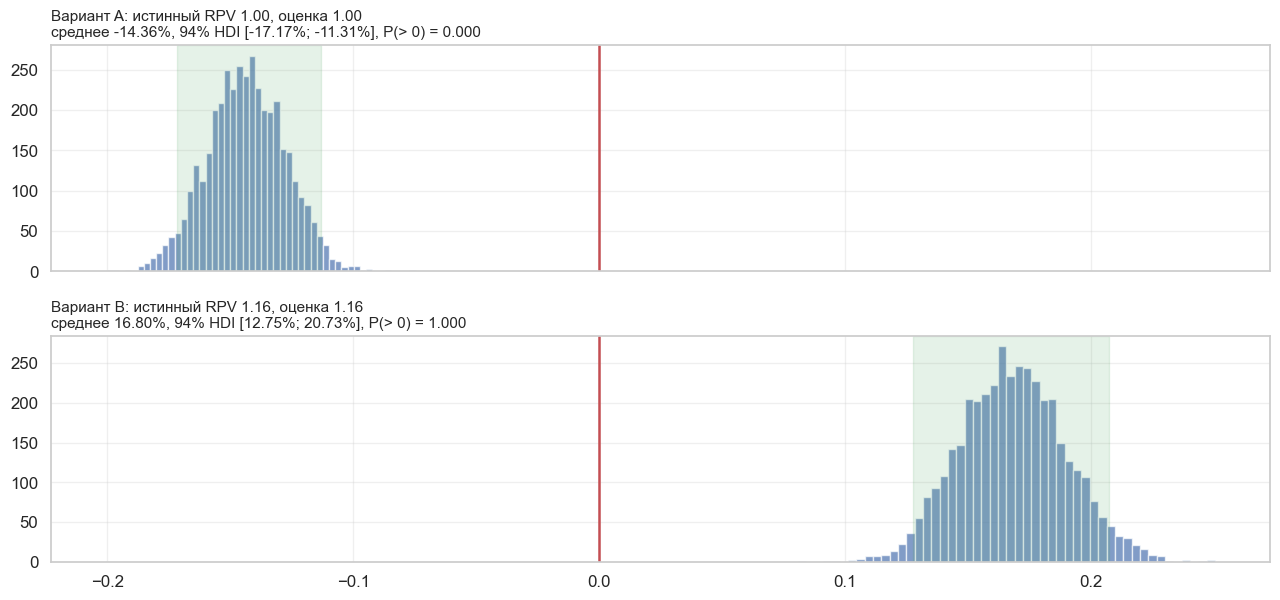

In [30]:
# Более высокая склонность к покупке и более высокая средняя стоимость покупки
_ = run_revenue_scenario([0.1, 0.11], [10, 10.5])

* 94% HDI для варианта B, как и ожидалось, выше 0: аплифт около 17% при истинных 16%, а оценка RPV совпала с истинной.

### Байесовский A/B/C на конверсиях

Здесь обратим внимание на анализ тестов с тремя и более вариантами — например, вместо того, чтобы тестировать одну целевую страницу, мы хотим протестировать несколько идей одновременно. Как определить, есть ли среди них победитель?

Здесь можно использовать два основных подхода:

* Возьмём A в качестве «контрольного варианта». Сравниваем другие варианты (B, C и т. д.) с A по одному.

* Для каждого варианта сравниваем с max() других вариантов.

Подход 1 интуитивно понятен большинству и легко объясним. Но что, если есть два варианта, которые оба превосходят контрольный, и мы хотим узнать, какой из них лучше? Мы не можем сделать такой вывод, используя отдельные распределения прироста. Подход 2 справляется с этим случаем — он фактически пытается определить, есть ли явный победитель или явный проигравший среди всех вариантов.

Ниже мы реализуем настройку модели для обоих подходов, очистив наш предыдущий код, чтобы он был обобщён на случай с n вариантами. Обратите внимание, что мы также можем использовать эту модель для случая с 2 вариантами.

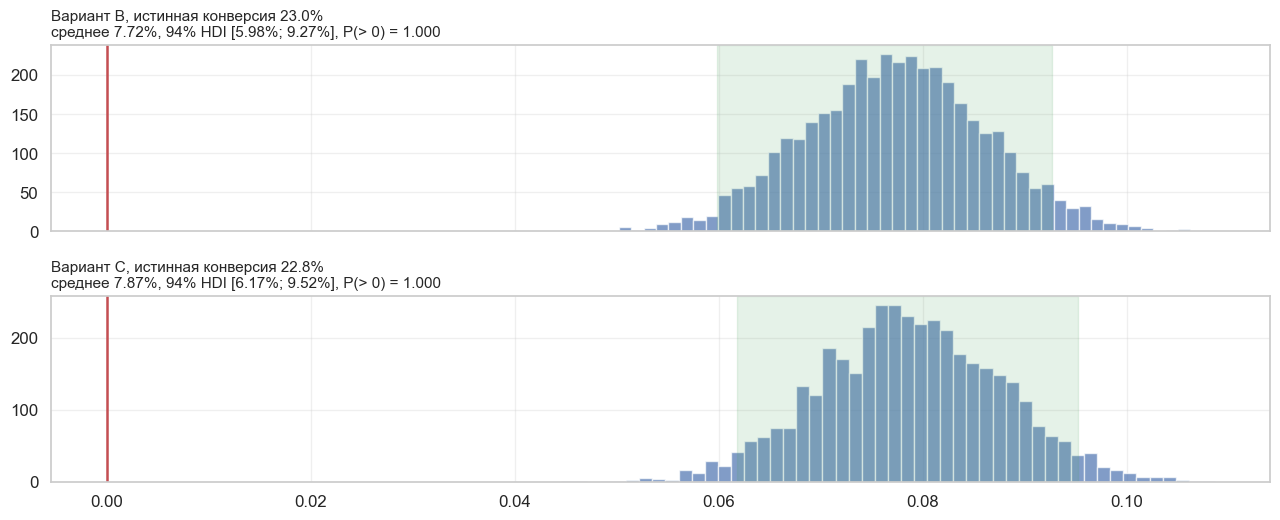

In [31]:
def run_abc_scenario(true_rates: list, comparison_method: str, samples_per_variant: int = 100_000) -> None:
    """Запускает многовариантный тест и рисует аплифт вариантов."""
    data = generate_binomial_data(true_rates, samples_per_variant, np.random.default_rng(10))
    with ConversionModel(BetaPrior(22, 78)).create_model(data, comparison_method):
        trace = pm.sample(chains=2, cores=1, draws=2000, tune=1000, random_seed=RANDOM_SEED, progressbar=False)

    shown = [1, 2] if comparison_method == 'compare_to_control' else [0, 1, 2]
    fig, axes = plt.subplots(len(shown), 1, figsize=(13, 2.7 * len(shown)), sharex=True)
    for ax, i in zip(axes, shown):
        uplift_panel(ax, trace.posterior[f'reluplift_{i}'].values, f"Вариант {'ABC'[i]}, истинная конверсия {true_rates[i]:.1%}")
    plt.tight_layout()
    plt.show()


# Подход 1: сравнение с контролем
run_abc_scenario([0.21, 0.23, 0.228], 'compare_to_control')

* Относительный аплифт для вариантов B и C показывает, что они явно лучше вариантов A (94% HDI значительно выше 0), примерно на 7–8% относительно.

* Однако мы не можем сделать вывод о наличии победителя между вариантами B и C, т.к. их HDI крайне сильно пересекаются.

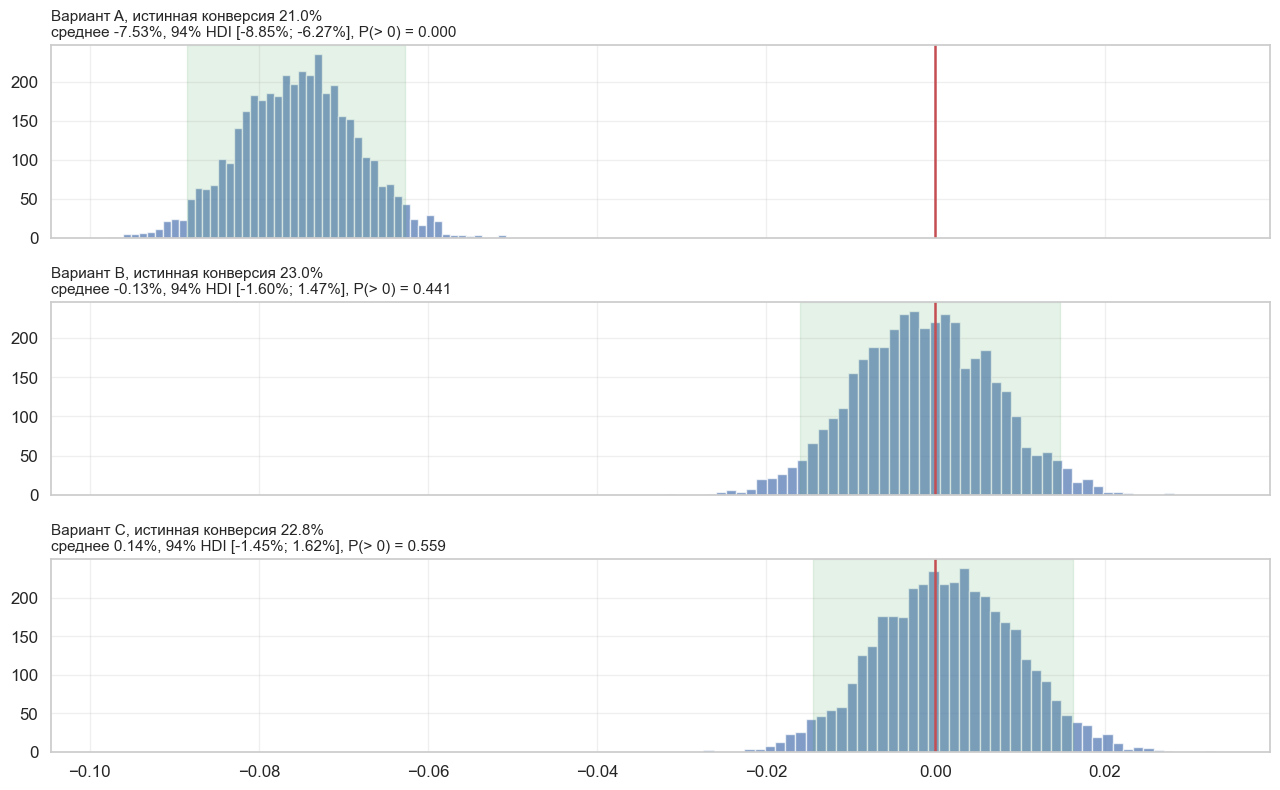

In [32]:
# Подход 2: сравнение с лучшим из остальных
run_abc_scenario([0.21, 0.23, 0.228], 'best_of_rest')

* График для варианта A показывает, что он явно проигрывает вариантам B и C (94% HDI для относительного подъёма для варианта A значительно ниже 0).

* Обратите внимание, что расчёт относительного аплифта для вариантов B и C фактически игнорирует вариант A. Это связано с тем, что, например, при расчёте относительного подъёма для варианта B максимальным из других вариантов, вероятно, будет вариант C. Аналогично, при расчёте относительного подъёма для варианта C он, вероятно, сравнивается с вариантом B.

* Графики для вариантов B и C показывают, что мы пока не можем назвать явного победителя среди двух вариантов, поскольку 94% HDI всё ещё пересекается с 0. Для обнаружения разницы между конверсиями 23% и 22.8% нам потребуется выборка большего размера.

* Одним из недостатков этого подхода является то, что мы не можем напрямую сказать, каков аплифт этих вариантов по сравнению с вариантом A (контрольным). Это число часто важно на практике, поскольку позволяет оценить общее влияние изменений, полученных в ходе A/B-тестирования, на всех пользователей. Однако мы можем получить это число приблизительно, переформулировав вопрос следующим образом: «Насколько вариант A хуже двух других?» (что показано в распределении относительного прироста для варианта A).

## Сравнение байесовского и частотного A/B-тестирования

Основные отличия подходов:

| Критерий | Частотный подход | Байесовский подход |
| :--- | :--- | :--- |
| Оцениваемые параметры | Неизвестные постоянные величины | Случайные величины с распределением |
| Результат | Решение на основе p-value | Вероятность утверждения и распределение эффекта |
| Контролируемый риск | Ошибка I рода | Ожидаемые потери при условии приора |
| Информация о прошлом поведении метрик | Нужна для расчёта размера групп | Может использоваться для приора и размера групп |
| Подглядывание | Нужны последовательные методы | Вероятность откалибрована только при верном приоре, ошибка I рода на A/A растёт так же |
| Сложность вычислений | Ниже | Выше, если модель не сопряжённая |
| Необходимое количество наблюдений | Зависит от дизайна | При широком приоре примерно то же; меньше только за счёт верной априорной информации |

Два мифа стоит отметить отдельно (см. также [разбор мифов](https://habr.com/ru/companies/X5Tech/articles/900032/)):

* **«Байесовский тест быстрее и чувствительнее».** С широким приором он численно совпадает с частотным. Приор лишь перераспределяет ошибки I и II рода, а выигрыш появляется, если он действительно верно отражает реальность.
* **«Можно смотреть в любой момент».** Постериор корректен при любой остановке только как утверждение при условии приора. Если важна доля ложных запусков на A/A, подглядывание опасно в той же мере, что и у частотного теста.

## Заключение

* Байесовский подход отвечает на вопрос «какова вероятность, что B лучше», но ответ зависит от модели и приора.
* С сопряжёнными приорами постериор считается по формуле, а MCMC нужен для сложных моделей.
* Работа с моделью — это цикл: априорная проверка, обучение, диагностика сходимости, апостериорная проверка, анализ чувствительности.
* Приор нужно центрировать на реальном уровне метрики и следить за масштабом параметров.
* $P(B > A) \ge 0.95$ при широком приоре близко к одностороннему тесту с $\alpha = 5\%$.
* Байесовский тест не отменяет подглядывание и не даёт бесплатной чувствительности, зато удобен для решений в деньгах и ожидаемых потерях.